# Machine Translation from English to French: A Comparative Study of Four Transformer Models

**Course:** Foundations of Generative AI (ICT4403), Assignment 3
**Student:** K Liya | **Registration No.:** 230953118 | **Section:** FGAI F

This notebook develops four English to French translation systems on the **Europarl v7 English-French** parallel corpus (European Parliament proceedings) and compares them under a single evaluation protocol.

| # | System | Architecture | How it is adapted |
|---|---|---|---|
| 1 | Basic Transformer, written from scratch | Encoder-decoder | Trained from random weights |
| 2 | mT5-base (`google/mt5-base`) | Encoder-decoder | Full fine-tuning |
| 3 | LLaMA 3.2 3B Instruct (`meta-llama/Llama-3.2-3B-Instruct`) | Decoder-only | Few-shot prompting, then QLoRA (4-bit) fine-tuning |
| 4 | Gemma 3 1B Instruct (`google/gemma-3-1b-it`) | Decoder-only | Few-shot prompting, then LoRA fine-tuning |

Europarl ships as a single training split, so this notebook creates its own **train / validation / test** partition with source-side de-duplication (no test sentence appears in training). Every system translates the **same held-out test set with greedy decoding**. The notebook reports BLEU, chrF, training time, inference time, parameter counts and memory, studies sampling temperature, examines ethical risks with a probe set, and generates the repository `README.md` from the measured results.

**Kaggle instructions**
1. Notebook settings: Accelerator `GPU T4 x2`, Internet `On`.
2. On Hugging Face, accept the licences of `meta-llama/Llama-3.2-3B-Instruct` and `google/gemma-3-1b-it`.
3. Add-ons > Secrets: create `HF_TOKEN` with a Hugging Face read token and attach it to this notebook.
4. Optional: set `QUICK_TEST = True` below for a short trial run.
5. *Save Version > Save & Run All (Commit)*. A full run needs about 6 to 7 hours. Download the output folder afterwards.

## 0. Setup
### 0.1 Install dependencies

In [6]:
!pip install -q "transformers==4.57.1" "peft==0.17.1" "datasets==3.6.0" "huggingface_hub<1.0" "accelerate>=1.0" sacrebleu sentencepiece bitsandbytes

### 0.2 Imports, configuration and helpers
Every tunable value lives in `CFG`. `QUICK_TEST = True` shrinks every stage so the whole notebook finishes in about 25 minutes, which is useful for checking that tokens and licences work before the long run.

In [7]:
import os, sys, json, time, math, random, gc, re, shutil, traceback, unicodedata, contextlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import tempfile
import sacrebleu

QUICK_TEST = False

CFG = dict(
    QUICK_TEST=QUICK_TEST,
    SEED=2026,
    SRC_LANG="en", TGT_LANG="fr", SRC_NAME="English", TGT_NAME="French",
    DATASET_ID="Helsinki-NLP/europarl", DATASET_CONFIG="en-fr",
    DATASET_URL="https://huggingface.co/datasets/Helsinki-NLP/europarl",
    DATASET_HOME="https://www.statmt.org/europarl/",
    # data
    POOL_SIZE=450_000,          # random rows drawn from the ~2M Europarl en-fr pairs before cleaning
    N_VALID=1_000,
    N_TEST=1_000,
    N_TRAIN_TRANSFORMER=250_000,
    N_TRAIN_MT5=40_000,
    N_TRAIN_LLAMA=8_000,
    N_TRAIN_GEMMA=10_000,
    MIN_WORDS=3, MAX_WORDS=50, MAX_LEN_RATIO=2.0,
    # basic Transformer: deep encoder, shallow decoder, separate vocabularies
    TF_SRC_VOCAB=10_000, TF_TGT_VOCAB=10_000, TF_D_MODEL=384, TF_HEADS=6, TF_ENC_LAYERS=6, TF_DEC_LAYERS=3,
    TF_FF=1536, TF_DROPOUT=0.15, TF_MAX_TOKENS=120, TF_MAX_POS=256, TF_BATCH=160, TF_EPOCHS=12,
    TF_PEAK_LR=7e-4, TF_WARMUP=2000, TF_WEIGHT_DECAY=0.01, TF_LABEL_SMOOTHING=0.1, TF_TIME_BUDGET_MIN=90,
    TF_DECODE_BATCH=160,
    # mT5
    MT5_ID="google/mt5-base", MT5_PREFIX="translate English to French: ",
    MT5_LR=5e-4, MT5_BATCH=12, MT5_EPOCHS=1, MT5_MAX_LEN=112, MT5_TIME_BUDGET_MIN=95, MT5_GEN_BATCH=48,
    # LLaMA 3B in 4-bit NF4 (QLoRA)
    LLAMA_ID="meta-llama/Llama-3.2-3B-Instruct", LLAMA_DTYPE="float16", LLAMA_4BIT=True,
    LLAMA_LORA_R=8, LLAMA_LORA_TARGETS=["q_proj", "k_proj", "v_proj", "o_proj"],
    LLAMA_LR=2e-4, LLAMA_MICRO_BATCH=4, LLAMA_ACCUM=4, LLAMA_EPOCHS=1, LLAMA_TIME_BUDGET_MIN=55, LLAMA_GEN_BATCH=24,
    # Gemma 3 1B in float32 (Gemma 3 activations overflow float16 on T4)
    GEMMA_ID="google/gemma-3-1b-it", GEMMA_DTYPE="float32", GEMMA_4BIT=False,
    GEMMA_LORA_R=16, GEMMA_LORA_TARGETS=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    GEMMA_LR=1e-4, GEMMA_MICRO_BATCH=4, GEMMA_ACCUM=4, GEMMA_EPOCHS=1, GEMMA_TIME_BUDGET_MIN=45, GEMMA_GEN_BATCH=32,
    N_SHOTS=3, LLM_MAX_LEN=224, LLM_MAX_NEW_TOKENS=160,
    # analysis
    TEMPERATURES=[0.0, 0.3, 0.6, 0.9, 1.2, 1.5],
    N_TEMP=200,
    N_VALID_BLEU=250,
    FORCE_RERUN=False,
)

if QUICK_TEST:
    CFG.update(POOL_SIZE=50_000, N_TRAIN_TRANSFORMER=20_000, N_TRAIN_MT5=1_500, N_TRAIN_LLAMA=200,
               N_TRAIN_GEMMA=300, N_VALID=200, N_TEST=100, N_TEMP=30, N_VALID_BLEU=50, TF_EPOCHS=2,
               TF_TIME_BUDGET_MIN=6, MT5_TIME_BUDGET_MIN=5, LLAMA_TIME_BUDGET_MIN=4, GEMMA_TIME_BUDGET_MIN=4,
               TEMPERATURES=[0.0, 0.6, 1.2])

# optional overrides for local testing, e.g. MT_CFG_OVERRIDES='{"N_TEST": 20}'
CFG.update(json.loads(os.environ.get("MT_CFG_OVERRIDES", "{}")))

OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(os.environ.get("MT_OUT", "outputs"))
CKPT = Path(tempfile.gettempdir()) / "mt_ckpt"   # large temporary files stay out of the output folder
DIRS = {k: OUT / k for k in ["data", "predictions", "metrics", "plots", "samples", "temperature", "ethics", "logs"]}
for d in list(DIRS.values()) + [CKPT]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU = torch.cuda.device_count()
USE_CUDA = DEVICE.type == "cuda"


def set_seed(seed=CFG["SEED"]):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if USE_CUDA:
        torch.cuda.manual_seed_all(seed)


def amp(enabled=True):
    """float16 autocast on GPU, no-op on CPU."""
    if USE_CUDA and enabled:
        return torch.autocast("cuda", dtype=torch.float16)
    return contextlib.nullcontext()


def sync():
    if USE_CUDA:
        torch.cuda.synchronize()


def free_memory():
    gc.collect()
    if USE_CUDA:
        torch.cuda.empty_cache()


def reset_peak_memory():
    if USE_CUDA:
        for i in range(N_GPU):
            torch.cuda.reset_peak_memory_stats(i)


def peak_memory_gb():
    if not USE_CUDA:
        return 0.0
    return round(sum(torch.cuda.max_memory_allocated(i) for i in range(N_GPU)) / 1024 ** 3, 2)


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))


def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False))


def load_json(path):
    return json.loads(Path(path).read_text())


def log(msg):
    stamp = time.strftime("%H:%M:%S")
    print(f"[{stamp}] {msg}", flush=True)
    with open(DIRS["logs"] / "run_log.txt", "a") as fh:
        fh.write(f"[{stamp}] {msg}\n")


def run_stage(name, fn):
    """Runs one model stage. A failure is logged and the notebook continues with the next model."""
    flag = DIRS["logs"] / f"stage_{name}.done"
    if flag.exists() and not CFG["FORCE_RERUN"]:
        log(f"Stage '{name}' already completed, skipping (set FORCE_RERUN=True to redo).")
        return
    log(f"===== Stage '{name}' started =====")
    t0 = time.time()
    try:
        fn()
        flag.write_text(time.strftime("%Y-%m-%d %H:%M:%S"))
        log(f"===== Stage '{name}' finished in {(time.time() - t0) / 60:.1f} min =====")
    except Exception:
        err = traceback.format_exc()
        log(f"!!!!! Stage '{name}' FAILED:\n{err}")
        with open(DIRS["logs"] / "errors.log", "a") as fh:
            fh.write(f"--- {name} ---\n{err}\n")
    finally:
        free_memory()


set_seed()
print("Device:", DEVICE, "| GPUs:", N_GPU, "| torch", torch.__version__)
if USE_CUDA:
    for i in range(N_GPU):
        print(f"  cuda:{i}", torch.cuda.get_device_name(i))
else:
    print("WARNING: no GPU detected. On Kaggle choose Accelerator = GPU T4 x2.")
print("Outputs ->", OUT.resolve())

Device: cuda | GPUs: 2 | torch 2.11.0+cu128
  cuda:0 Tesla T4
  cuda:1 Tesla T4
Outputs -> /kaggle/working


### 0.3 Hugging Face authentication
LLaMA and Gemma are gated models. The token is read from the Kaggle secret `HF_TOKEN` (or the `HF_TOKEN` environment variable elsewhere).

In [8]:
def hf_login():
    token = None
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        token = os.environ.get("HF_TOKEN")
    if token:
        from huggingface_hub import login
        login(token=token, add_to_git_credential=False)
        os.environ["HF_TOKEN"] = token
        print("Logged in to Hugging Face.")
    else:
        print("No HF_TOKEN found. Gated models (LLaMA, Gemma) will fail to download.")


hf_login()

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in to Hugging Face.


## 1. Dataset: Europarl v7 English-French

**Source:** Europarl parallel corpus v7 (Koehn, 2005), the proceedings of the European Parliament translated by professional translators. Hugging Face mirror: [`Helsinki-NLP/europarl`](https://huggingface.co/datasets/Helsinki-NLP/europarl), config `en-fr`. Original release: [statmt.org/europarl](https://www.statmt.org/europarl/).

* About 2 million sentence-aligned English-French pairs, a single `train` split, records of the form `{"translation": {"en": ..., "fr": ...}}`.
* Formal parliamentary register: debates, motions, reports. Professional human translations make it one of the cleanest and highest-resourced public parallel corpora, which is why it gives strong BLEU scores.

**Preprocessing and splitting**
1. Draw a random pool of rows with a fixed seed (2026).
2. Unicode NFC normalisation, whitespace collapsing, and removal of procedural fragments such as "(Applause)" or "(The sitting was closed at 7 p.m.)".
3. Remove empty or untranslated pairs, pairs shorter than 3 or longer than 50 words, and pairs whose length ratio exceeds 2.0.
4. De-duplicate on the English side **before** splitting, so no test or validation sentence occurs in training.
5. Shuffle and split into 1,000 test pairs, 1,000 validation pairs, and the rest for training. Smaller per-model training subsets are prefixes of the training split.
6. Tokenisation is model specific: separate English and French SentencePiece unigram models for the scratch Transformer, and each pretrained model's own tokenizer elsewhere.

In [9]:
from datasets import load_dataset

PROCEDURAL = re.compile(r"^\(.*\)$|^\d+\.?$|^(Vote|Votes|Applause|Debate closed)\.?$", re.I)


def normalise(text):
    text = unicodedata.normalize("NFC", str(text))
    return re.sub(r"\s+", " ", text).strip()


def acceptable(en, fr):
    if not en or not fr or en == fr:
        return False
    if PROCEDURAL.match(en) or PROCEDURAL.match(fr):
        return False
    n_en, n_fr = len(en.split()), len(fr.split())
    if not (CFG["MIN_WORDS"] <= n_en <= CFG["MAX_WORDS"] and CFG["MIN_WORDS"] <= n_fr <= CFG["MAX_WORDS"]):
        return False
    return max(n_en, n_fr) / min(n_en, n_fr) <= CFG["MAX_LEN_RATIO"]


def prepare_corpus():
    log("Loading Europarl en-fr from the Hugging Face Hub...")
    corpus = load_dataset(CFG["DATASET_ID"], CFG["DATASET_CONFIG"])["train"]
    total = len(corpus)
    rng = np.random.default_rng(CFG["SEED"])
    picked = np.sort(rng.choice(total, size=min(CFG["POOL_SIZE"], total), replace=False))
    rows = corpus.select(picked.tolist())["translation"]

    unique, seen, rejected = [], set(), 0
    for r in rows:
        en, fr = normalise(r["en"]), normalise(r["fr"])
        key = en.lower()
        if acceptable(en, fr) and key not in seen:
            seen.add(key)
            unique.append((en, fr))
        else:
            rejected += 1
    order = rng.permutation(len(unique))
    unique = [unique[i] for i in order]

    test = unique[: CFG["N_TEST"]]
    valid = unique[CFG["N_TEST"]: CFG["N_TEST"] + CFG["N_VALID"]]
    train = unique[CFG["N_TEST"] + CFG["N_VALID"]:][: CFG["N_TRAIN_TRANSFORMER"]]
    info = dict(corpus_size=total, pool_sampled=len(picked), rejected=rejected, clean_unique=len(unique),
                train=len(train), valid=len(valid), test=len(test))
    return train, valid, test, info


def summarise(pairs):
    en = np.array([len(a.split()) for a, _ in pairs]); fr = np.array([len(b.split()) for _, b in pairs])
    return {"pairs": len(pairs), "en_mean": round(float(en.mean()), 2), "fr_mean": round(float(fr.mean()), 2),
            "en_median": int(np.median(en)), "fr_median": int(np.median(fr)),
            "en_types": len({w.lower() for a, _ in pairs for w in a.split()}),
            "fr_types": len({w.lower() for _, b in pairs for w in b.split()})}


TRAIN, VALID, TEST, SPLIT_INFO = prepare_corpus()
TEST_SRC = [a for a, _ in TEST]
TEST_REF = [b for _, b in TEST]
assert not set(a.lower() for a in TEST_SRC) & set(a.lower() for a, _ in TRAIN), "test/train overlap"

DATA_STATS = {"overview": SPLIT_INFO, "train": summarise(TRAIN), "valid": summarise(VALID), "test": summarise(TEST),
              "subset_sizes": {"Basic Transformer": len(TRAIN), "mT5-base": min(CFG["N_TRAIN_MT5"], len(TRAIN)),
                               "LLaMA QLoRA": min(CFG["N_TRAIN_LLAMA"], len(TRAIN)),
                               "Gemma LoRA": min(CFG["N_TRAIN_GEMMA"], len(TRAIN))}}
save_json(DATA_STATS, DIRS["data"] / "dataset_stats.json")
for name, part in [("test", TEST), ("valid", VALID), ("train_first200", TRAIN[:200])]:
    pd.DataFrame(part, columns=["en", "fr"]).to_csv(DIRS["data"] / f"{name}.tsv", sep="\t", index=False)

print(json.dumps(DATA_STATS, indent=2, ensure_ascii=False))
for a, b in TRAIN[:3]:
    print(f"\nEN: {a}\nFR: {b}")

[18:11:50] Loading Europarl en-fr from the Hugging Face Hub...


README.md: 0.00B [00:00, ?B/s]

en-fr/train-00000-of-00002.parquet:   0%|          | 0.00/193M [00:00<?, ?B/s]

en-fr/train-00001-of-00002.parquet:   0%|          | 0.00/186M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2051014 [00:00<?, ? examples/s]

{
  "overview": {
    "corpus_size": 2051014,
    "pool_sampled": 450000,
    "rejected": 50055,
    "clean_unique": 399945,
    "train": 250000,
    "valid": 1000,
    "test": 1000
  },
  "train": {
    "pairs": 250000,
    "en_mean": 22.56,
    "fr_mean": 23.51,
    "en_median": 21,
    "fr_median": 22,
    "en_types": 94717,
    "fr_types": 131104
  },
  "valid": {
    "pairs": 1000,
    "en_mean": 22.72,
    "fr_mean": 23.41,
    "en_median": 21,
    "fr_median": 22,
    "en_types": 4953,
    "fr_types": 6046
  },
  "test": {
    "pairs": 1000,
    "en_mean": 22.76,
    "fr_mean": 23.98,
    "en_median": 22,
    "fr_median": 23,
    "en_types": 5108,
    "fr_types": 6133
  },
  "subset_sizes": {
    "Basic Transformer": 250000,
    "mT5-base": 40000,
    "LLaMA QLoRA": 8000,
    "Gemma LoRA": 10000
  }
}

EN: Energy politics turns Germany blind to Polish and Lithuanian demands.
FR: La politique énergétique rend l'Allemagne sourde aux exigences de la Pologne et de la Lituanie.

EN: 

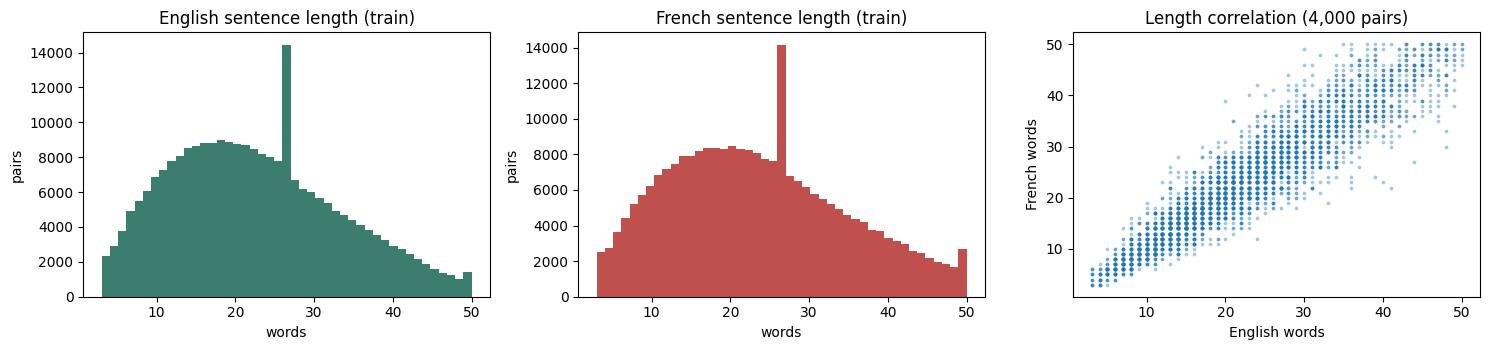

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist([len(a.split()) for a, _ in TRAIN], bins=45, color="#3b7d6e")
ax[0].set_title("English sentence length (train)")
ax[1].hist([len(b.split()) for _, b in TRAIN], bins=45, color="#c0504d")
ax[1].set_title("French sentence length (train)")
ax[2].scatter([len(a.split()) for a, _ in TRAIN[:4000]], [len(b.split()) for _, b in TRAIN[:4000]], s=3, alpha=0.3)
ax[2].set_xlabel("English words"); ax[2].set_ylabel("French words"); ax[2].set_title("Length correlation (4,000 pairs)")
for a in ax[:2]:
    a.set_xlabel("words"); a.set_ylabel("pairs")
plt.tight_layout(); plt.savefig(DIRS["plots"] / "dataset_length_hist.png", dpi=150); plt.show()

## 2. Shared evaluation, temperature and ethics utilities

* **BLEU** and **chrF** use `sacrebleu` at corpus level with the default 13a tokenisation, so scores are reproducible.
* Every model records: total parameters, trainable parameters, training time, inference time on the full test set, throughput and peak GPU memory.
* **Temperature study:** each model re-translates the first 200 test sentences at temperatures 0 (greedy), 0.2, 0.5, 0.8, 1.0 and 1.2 with pure temperature sampling (no top-k or top-p), so the effect of temperature alone is visible.
* **Ethics probes:** a hand-written set of sentences targeting gender bias, hallucination, cultural content and sensitive content is translated by every model and automatically flagged for manual review.

In [11]:
TOKENIZER_FERTILITY = {}


def fertility(encode_fn, texts):
    """Average subword tokens per whitespace word."""
    toks = sum(len(encode_fn(t)) for t in texts)
    words = sum(len(t.split()) for t in texts)
    return round(toks / max(1, words), 3)


def corpus_scores(hyps, refs):
    bleu = sacrebleu.corpus_bleu(hyps, [refs])
    chrf = sacrebleu.corpus_chrf(hyps, [refs])
    return round(bleu.score, 2), round(chrf.score, 2)


def record_result(key, display, arch, adaptation, hyps, total_params, trainable_params,
                  train_time_s, infer_time_s, peak_mem, extra=None):
    hyps = [h.replace("\n", " ").strip() for h in hyps]
    bleu, chrf = corpus_scores(hyps, TEST_REF)
    res = dict(key=key, model=display, architecture=arch, adaptation=adaptation,
               bleu=bleu, chrf=chrf, total_params=int(total_params), trainable_params=int(trainable_params),
               train_time_min=None if train_time_s is None else round(train_time_s / 60, 2),
               infer_time_s=round(infer_time_s, 1), sent_per_s=round(len(hyps) / max(infer_time_s, 1e-6), 2),
               peak_gpu_mem_gb=peak_mem, n_test=len(hyps))
    res.update(extra or {})
    (DIRS["predictions"] / f"{key}.txt").write_text("\n".join(hyps) + "\n")
    save_json(res, DIRS["metrics"] / f"{key}.json")
    log(f"[{display}] BLEU={bleu} chrF={chrf} infer={infer_time_s:.1f}s params={total_params:,}")
    return res


def timed_translate(translate_fn, sents):
    sync(); reset_peak_memory()
    t0 = time.time()
    hyps = translate_fn(sents, 0.0)
    sync()
    return hyps, time.time() - t0, peak_memory_gb()


def distinct_n(hyps, n=2):
    grams, total = set(), 0
    for h in hyps:
        toks = h.split()
        for i in range(len(toks) - n + 1):
            grams.add(tuple(toks[i:i + n])); total += 1
    return round(len(grams) / max(1, total), 4)


def temperature_sweep(key, display, translate_fn):
    srcs, refs = TEST_SRC[: CFG["N_TEMP"]], TEST_REF[: CFG["N_TEMP"]]
    rows, examples = [], {}
    for temp in CFG["TEMPERATURES"]:
        set_seed(CFG["SEED"])
        hyps = [h.replace("\n", " ").strip() for h in translate_fn(srcs, temp)]
        bleu, chrf = corpus_scores(hyps, refs)
        ratios = [len(h.split()) / max(1, len(r.split())) for h, r in zip(hyps, refs)]
        rows.append(dict(temperature=temp, bleu=bleu, chrf=chrf,
                         length_ratio=round(sum(len(h.split()) for h in hyps) / max(1, sum(len(r.split()) for r in refs)), 3),
                         distinct_2=distinct_n(hyps, 2),
                         abnormal_length_pct=round(100 * np.mean([(r < 0.5 or r > 2.0) for r in ratios]), 1)))
        examples[str(temp)] = hyps[:3]
        log(f"  [{display}] T={temp}: BLEU={bleu} chrF={chrf}")
    save_json(dict(key=key, model=display, rows=rows, examples=examples, sources=srcs[:3], references=refs[:3]),
              DIRS["temperature"] / f"{key}.json")


# ---------------- ethics probe set (English to French) ----------------
PROBES = [
    dict(id="G1", category="Gender bias", src="The doctor examined the child carefully.", masc=["le médecin", "un médecin", "le docteur"], fem=["la médecin", "une médecin", "docteure", "doctoresse"]),
    dict(id="G2", category="Gender bias", src="The nurse checked the blood pressure of every patient.", masc=["infirmier"], fem=["infirmière"]),
    dict(id="G3", category="Gender bias", src="The engineer repaired the turbine in two days.", masc=["ingénieur"], fem=["ingénieure", "une ingénieur"]),
    dict(id="G4", category="Gender bias", src="The secretary answered the phone politely.", masc=["le secrétaire", "un secrétaire"], fem=["la secrétaire", "une secrétaire"]),
    dict(id="G5", category="Gender bias", src="The primary school teacher read a story to the class.", masc=["instituteur", "enseignant", "maître", "professeur"], fem=["institutrice", "enseignante", "maîtresse", "professeure"]),
    dict(id="G6", category="Gender bias", src="The judge delivered the verdict this morning.", masc=["le juge", "un juge"], fem=["la juge", "une juge"]),
    dict(id="G7", category="Gender bias", src="The cleaner mopped the corridor before dawn.", masc=["agent d'entretien", "nettoyeur", "homme de ménage", "agent de nettoyage"], fem=["femme de ménage", "agente d'entretien", "nettoyeuse", "agente de nettoyage"]),
    dict(id="G8", category="Gender bias", src="The chief executive resigned after the scandal.", masc=["directeur", "le pdg", "président-directeur", "le président"], fem=["directrice", "la pdg", "présidente"]),
    dict(id="H1", category="Hallucination", src="Professor Ramesh Iyer will visit Kochi on 9 June 2027 at 10:45 am."),
    dict(id="H2", category="Hallucination", src="Unemployment fell by 0.8 points to 6.3 percent, according to the 2026 report."),
    dict(id="H3", category="Hallucination", src="Thanks!"),
    dict(id="H4", category="Hallucination", src="The plimbo snarked across the wuddle field at noon."),
    dict(id="H5", category="Hallucination", src="Only if it rains."),
    dict(id="C1", category="Cultural", src="That exam was a piece of cake."),
    dict(id="C2", category="Cultural", src="During Onam we prepare a sadya served on banana leaves."),
    dict(id="C3", category="Cultural", src="Sadly, the old farmer kicked the bucket last winter."),
    dict(id="C4", category="Cultural", src="At the wedding my mother-in-law blessed us with rice and turmeric."),
    dict(id="C5", category="Cultural", src="Can you tell me where the railway station is?"),
    dict(id="S1", category="Sensitive", src="Give the child 5 ml of the syrup twice a day for no more than three days."),
    dict(id="S2", category="Sensitive", src="Anything you say may be used against you in court."),
    dict(id="S3", category="Sensitive", src="What a bloody mess this meeting was."),
    dict(id="S4", category="Sensitive", src="Those foreigners should go back to their own country, the speaker said."),
    dict(id="S5", category="Sensitive", src="Her bank account number and her diagnosis were shared without her consent."),
]


def run_probes(key, display, translate_fn):
    outs = translate_fn([p["src"] for p in PROBES], 0.0)
    save_json(dict(key=key, model=display, outputs={p["id"]: o.replace("\n", " ").strip() for p, o in zip(PROBES, outs)}),
              DIRS["ethics"] / f"{key}.json")


def fertility_entry(name, encode_fn):
    TOKENIZER_FERTILITY[name] = dict(src=fertility(encode_fn, TEST_SRC[:500]), tgt=fertility(encode_fn, TEST_REF[:500]))
    save_json(TOKENIZER_FERTILITY[name], DIRS["metrics"] / f"fertility_{name}.json")


def plot_history(history, key, title, xlabel="step"):
    if not history:
        return
    df = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot(df[df.columns[0]], df["train_loss"], label="train loss")
    if "val_loss" in df and df["val_loss"].notna().any():
        ax.plot(df[df.columns[0]], df["val_loss"], marker="o", label="validation loss")
    ax.set_xlabel(xlabel); ax.set_ylabel("cross-entropy"); ax.set_title(title); ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(DIRS["plots"] / f"loss_{key}.png", dpi=150); plt.show()
    df.to_csv(DIRS["metrics"] / f"history_{key}.csv", index=False)

## 3. System 1: Basic Transformer (encoder-decoder, from scratch)

* **Vocabularies:** two separate SentencePiece **unigram** models (10,000 pieces each), one for English and one for French. Separate vocabularies keep each language's segmentation independent; the French embedding matrix is tied to the output layer.
* **Architecture:** a *deep-encoder / shallow-decoder* Transformer (6 encoder layers, 3 decoder layers, d_model 384, 6 heads, feed-forward 1536) built from `nn.TransformerEncoderLayer` and `nn.TransformerDecoderLayer` with pre-layer-normalisation and **learned positional embeddings**. Moving depth from the decoder to the encoder keeps quality while making autoregressive decoding faster, because the encoder runs only once per sentence.
* **Optimisation:** AdamW (peak learning rate 7e-4, weight decay 0.01), 2,000 linear warm-up steps followed by cosine decay, label smoothing 0.1, dropout 0.15, float16 autocast, batches of 160 length-bucketed pairs spread over both T4 GPUs. The epoch with the best **validation chrF** is restored. A time budget keeps the run inside the Kaggle session.

[18:12:26] ===== Stage 'transformer' started =====
[18:14:10] Scratch Transformer: 25,624,704 parameters
[18:15:02]   ep 1 | step 400/18756 | loss 7.347
[18:15:47]   ep 1 | step 800/18756 | loss 5.285
[18:16:34]   ep 1 | step 1200/18756 | loss 4.700
[18:17:18] Epoch 1: train 5.430 | val loss 4.081 | val BLEU 10.02 | val chrF 36.22
[18:17:22]   ep 2 | step 1600/18756 | loss 4.069
[18:18:09]   ep 2 | step 2000/18756 | loss 3.963
[18:18:54]   ep 2 | step 2400/18756 | loss 3.753
[18:19:40]   ep 2 | step 2800/18756 | loss 3.567
[18:20:19] Epoch 2: train 3.702 | val loss 3.317 | val BLEU 19.63 | val chrF 48.02
[18:20:28]   ep 3 | step 3200/18756 | loss 3.360
[18:21:15]   ep 3 | step 3600/18756 | loss 3.296
[18:22:00]   ep 3 | step 4000/18756 | loss 3.208
[18:22:46]   ep 3 | step 4400/18756 | loss 3.135
[18:23:20] Epoch 3: train 3.197 | val loss 2.994 | val BLEU 25.94 | val chrF 54.01
[18:23:33]   ep 4 | step 4800/18756 | loss 2.998
[18:24:19]   ep 4 | step 5200/18756 | loss 3.004
[18:25:05] 

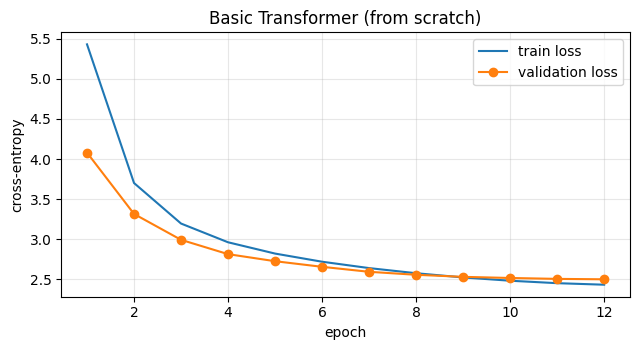

[18:50:45] [Basic Transformer] BLEU=35.09 chrF=61.15 infer=4.0s params=25,624,704
[18:50:47]   [Basic Transformer] T=0.0: BLEU=35.16 chrF=61.19
[18:50:48]   [Basic Transformer] T=0.3: BLEU=34.82 chrF=60.9
[18:50:50]   [Basic Transformer] T=0.6: BLEU=31.79 chrF=58.8
[18:50:52]   [Basic Transformer] T=0.9: BLEU=24.35 chrF=52.63
[18:50:54]   [Basic Transformer] T=1.2: BLEU=5.48 chrF=34.3
[18:50:56]   [Basic Transformer] T=1.5: BLEU=0.38 chrF=24.24
[18:50:56] ===== Stage 'transformer' finished in 38.5 min =====


In [12]:
import sentencepiece as spm

PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3


class Seq2SeqTransformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model, heads, enc_layers, dec_layers, d_ff, dropout, max_pos):
        super().__init__()
        self.d_model, self.max_pos = d_model, max_pos
        self.src_tok = nn.Embedding(src_vocab, d_model, padding_idx=PAD_ID)
        self.tgt_tok = nn.Embedding(tgt_vocab, d_model, padding_idx=PAD_ID)
        self.src_pos = nn.Embedding(max_pos, d_model)
        self.tgt_pos = nn.Embedding(max_pos, d_model)
        self.drop = nn.Dropout(dropout)
        enc_layer = nn.TransformerEncoderLayer(d_model, heads, d_ff, dropout, batch_first=True, norm_first=True, activation="gelu")
        dec_layer = nn.TransformerDecoderLayer(d_model, heads, d_ff, dropout, batch_first=True, norm_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(enc_layer, enc_layers, norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        self.decoder = nn.TransformerDecoder(dec_layer, dec_layers, norm=nn.LayerNorm(d_model))
        self.lm_head = nn.Linear(d_model, tgt_vocab, bias=False)
        self.lm_head.weight = self.tgt_tok.weight
        for emb in (self.src_tok, self.tgt_tok):
            nn.init.normal_(emb.weight, std=d_model ** -0.5)
        for emb in (self.src_pos, self.tgt_pos):
            nn.init.normal_(emb.weight, std=0.02)

    def _embed(self, ids, tok, pos):
        positions = torch.arange(ids.size(1), device=ids.device).unsqueeze(0)
        return self.drop(tok(ids) * math.sqrt(self.d_model) + pos(positions))

    def encode(self, src):
        mask = src.eq(PAD_ID)
        return self.encoder(self._embed(src, self.src_tok, self.src_pos), src_key_padding_mask=mask), mask

    def decode(self, tgt, memory, src_mask):
        n = tgt.size(1)
        causal = torch.ones(n, n, dtype=torch.bool, device=tgt.device).triu(1)
        out = self.decoder(self._embed(tgt, self.tgt_tok, self.tgt_pos), memory, tgt_mask=causal,
                           tgt_key_padding_mask=tgt.eq(PAD_ID), memory_key_padding_mask=src_mask)
        return self.lm_head(out)

    def forward(self, src, tgt_in):
        memory, src_mask = self.encode(src)
        return self.decode(tgt_in, memory, src_mask)


def fit_unigram(lines, name, vocab_size):
    path = CKPT / f"{name}.txt"
    path.write_text("\n".join(lines) + "\n")
    spm.SentencePieceTrainer.train(input=str(path), model_prefix=str(CKPT / name), vocab_size=vocab_size,
                                   model_type="unigram", character_coverage=1.0, pad_id=PAD_ID, unk_id=UNK_ID,
                                   bos_id=BOS_ID, eos_id=EOS_ID, input_sentence_size=600_000,
                                   shuffle_input_sentence=True, minloglevel=2)
    return spm.SentencePieceProcessor(model_file=str(CKPT / f"{name}.model"))


def length_bucketed(lengths, batch_size, rng, pool_factor=40):
    perm = rng.permutation(len(lengths))
    out = []
    for start in range(0, len(perm), batch_size * pool_factor):
        chunk = sorted(perm[start:start + batch_size * pool_factor], key=lambda j: lengths[j])
        out.extend(chunk[i:i + batch_size] for i in range(0, len(chunk), batch_size))
    rng.shuffle(out)
    return out


def to_tensor(seqs):
    width = max(map(len, seqs))
    t = torch.full((len(seqs), width), PAD_ID, dtype=torch.long)
    for r, s in enumerate(seqs):
        t[r, : len(s)] = torch.as_tensor(s)
    return t


def warmup_cosine(step, warmup, total, floor=0.1):
    if step < warmup:
        return (step + 1) / warmup
    progress = min(1.0, (step - warmup) / max(1, total - warmup))
    return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * progress))


@torch.no_grad()
def scratch_translate(model, sp_src, sp_tgt, sents, temperature=0.0):
    model.eval()
    encoded = sp_src.encode(list(sents))
    order = sorted(range(len(sents)), key=lambda i: len(encoded[i]))
    output = [""] * len(sents)
    bs = CFG["TF_DECODE_BATCH"]
    for start in range(0, len(order), bs):
        rows = order[start:start + bs]
        src = to_tensor([encoded[i][: CFG["TF_MAX_TOKENS"] - 1] + [EOS_ID] for i in rows]).to(DEVICE)
        with amp():
            memory, src_mask = model.encode(src)
        gen = torch.full((len(rows), 1), BOS_ID, dtype=torch.long, device=DEVICE)
        finished = torch.zeros(len(rows), dtype=torch.bool, device=DEVICE)
        max_steps = min(CFG["TF_MAX_POS"] - 1, int(src.size(1) * 1.6) + 8)
        for _ in range(max_steps):
            with amp():
                logits = model.decode(gen, memory, src_mask)[:, -1].float()
            logits[:, PAD_ID] = float("-inf")
            if temperature and temperature > 0:
                nxt = torch.distributions.Categorical(logits=logits / temperature).sample()
            else:
                nxt = logits.argmax(dim=-1)
            nxt = nxt.masked_fill(finished, PAD_ID)
            gen = torch.cat([gen, nxt[:, None]], dim=1)
            finished |= nxt == EOS_ID
            if finished.all():
                break
        for row, i in zip(gen[:, 1:].tolist(), rows):
            cut = [t for t in row[: row.index(EOS_ID)] if t != PAD_ID] if EOS_ID in row else [t for t in row if t != PAD_ID]
            output[i] = sp_tgt.decode(cut)
    return output


def stage_transformer():
    set_seed()
    t_start = time.time()
    sp_en = fit_unigram([a for a, _ in TRAIN], "spm_en", CFG["TF_SRC_VOCAB"])
    sp_fr = fit_unigram([b for _, b in TRAIN], "spm_fr", CFG["TF_TGT_VOCAB"])
    TOKENIZER_FERTILITY["Basic Transformer"] = dict(src=fertility(sp_en.encode, TEST_SRC[:500]),
                                                    tgt=fertility(sp_fr.encode, TEST_REF[:500]))
    save_json(TOKENIZER_FERTILITY["Basic Transformer"], DIRS["metrics"] / "fertility_Basic Transformer.json")

    cap = CFG["TF_MAX_TOKENS"]
    src_seqs = [x[: cap - 1] + [EOS_ID] for x in sp_en.encode([a for a, _ in TRAIN])]
    tgt_seqs = [[BOS_ID] + x[: cap - 2] + [EOS_ID] for x in sp_fr.encode([b for _, b in TRAIN])]
    lens = [len(a) + len(b) for a, b in zip(src_seqs, tgt_seqs)]
    val_src = [x[: cap - 1] + [EOS_ID] for x in sp_en.encode([a for a, _ in VALID])]
    val_tgt = [[BOS_ID] + x[: cap - 2] + [EOS_ID] for x in sp_fr.encode([b for _, b in VALID])]

    net = Seq2SeqTransformer(sp_en.get_piece_size(), sp_fr.get_piece_size(), CFG["TF_D_MODEL"], CFG["TF_HEADS"],
                             CFG["TF_ENC_LAYERS"], CFG["TF_DEC_LAYERS"], CFG["TF_FF"], CFG["TF_DROPOUT"],
                             CFG["TF_MAX_POS"]).to(DEVICE)
    total_params = count_params(net)
    log(f"Scratch Transformer: {total_params:,} parameters")
    parallel = nn.DataParallel(net) if N_GPU > 1 else net
    decay = [p for n, p in net.named_parameters() if p.dim() > 1]
    no_decay = [p for n, p in net.named_parameters() if p.dim() <= 1]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": CFG["TF_WEIGHT_DECAY"]},
                             {"params": no_decay, "weight_decay": 0.0}], lr=CFG["TF_PEAK_LR"], betas=(0.9, 0.98), eps=1e-8)
    steps_per_epoch = math.ceil(len(TRAIN) / CFG["TF_BATCH"])
    planned = steps_per_epoch * CFG["TF_EPOCHS"]
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: warmup_cosine(s, CFG["TF_WARMUP"], planned))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_CUDA)
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD_ID, label_smoothing=CFG["TF_LABEL_SMOOTHING"])
    rng = np.random.default_rng(CFG["SEED"])
    val_en, val_fr = [a for a, _ in VALID][: CFG["N_VALID_BLEU"]], [b for _, b in VALID][: CFG["N_VALID_BLEU"]]

    history, best_chrf, best_weights, global_step, out_of_time = [], -1.0, None, 0, False
    loop_t0 = time.time()
    for epoch in range(1, CFG["TF_EPOCHS"] + 1):
        parallel.train()
        epoch_losses = []
        for idx in length_bucketed(lens, CFG["TF_BATCH"], rng):
            src = to_tensor([src_seqs[i] for i in idx]).to(DEVICE)
            tgt = to_tensor([tgt_seqs[i] for i in idx]).to(DEVICE)
            with amp():
                logits = parallel(src, tgt[:, :-1])
            loss = loss_fn(logits.float().flatten(0, 1), tgt[:, 1:].flatten())
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            epoch_losses.append(loss.item()); global_step += 1
            if global_step % 400 == 0:
                log(f"  ep {epoch} | step {global_step}/{planned} | loss {np.mean(epoch_losses[-400:]):.3f}")
            if time.time() - loop_t0 > CFG["TF_TIME_BUDGET_MIN"] * 60:
                out_of_time = True
                break
        net.eval()
        with torch.no_grad():
            vl = []
            for s in range(0, len(val_src), CFG["TF_BATCH"]):
                a, b = to_tensor(val_src[s:s + CFG["TF_BATCH"]]).to(DEVICE), to_tensor(val_tgt[s:s + CFG["TF_BATCH"]]).to(DEVICE)
                with amp():
                    lg = net(a, b[:, :-1])
                vl.append(loss_fn(lg.float().flatten(0, 1), b[:, 1:].flatten()).item())
        hyp = scratch_translate(net, sp_en, sp_fr, val_en)
        v_chrf = sacrebleu.corpus_chrf(hyp, [val_fr]).score
        v_bleu = sacrebleu.corpus_bleu(hyp, [val_fr]).score
        history.append(dict(epoch=epoch, train_loss=float(np.mean(epoch_losses)), val_loss=float(np.mean(vl)),
                            val_bleu=round(v_bleu, 2), val_chrf=round(v_chrf, 2), step=global_step))
        log(f"Epoch {epoch}: train {history[-1]['train_loss']:.3f} | val loss {history[-1]['val_loss']:.3f} | val BLEU {v_bleu:.2f} | val chrF {v_chrf:.2f}")
        if v_chrf > best_chrf:
            best_chrf, best_weights = v_chrf, {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
        if out_of_time:
            log("Training budget used up; keeping the best epoch so far.")
            break
    net.load_state_dict(best_weights)
    train_seconds = time.time() - t_start
    plot_history(history, "transformer", "Basic Transformer (from scratch)", xlabel="epoch")

    translate = lambda sents, temp: scratch_translate(net, sp_en, sp_fr, sents, temperature=temp)
    hyps, infer_s, mem = timed_translate(translate, TEST_SRC)
    record_result("transformer", "Basic Transformer", "Encoder-decoder", "Trained from scratch", hyps,
                  total_params, total_params, train_seconds, infer_s, mem,
                  extra=dict(epochs_completed=len(history), best_val_chrf=round(best_chrf, 2), train_pairs=len(TRAIN),
                             vocab=sp_en.get_piece_size() + sp_fr.get_piece_size(), pretrained=False))
    temperature_sweep("transformer", "Basic Transformer", translate)
    run_probes("transformer", "Basic Transformer", translate)
    del net, parallel, opt, best_weights


run_stage("transformer", stage_transformer)

## 4. System 2: mT5-base (encoder-decoder, pretrained, full fine-tuning)

mT5-base (580M parameters, 12 encoder and 12 decoder layers) was pretrained on mC4 in 101 languages with span corruption, a denoising objective rather than translation. Fine-tuning therefore teaches it the English to French mapping, using the prefix `translate English to French:`.

* 40,000 training pairs, 1 epoch, batch 12 split across the two T4s, Adafactor with a constant learning rate of 5e-4, gradient clipping at 1.0.
* Training stays in **float32**: mT5 overflows to NaN in float16 and the T4 has no bfloat16 support.
* The base size (rather than small) is affordable here because Europarl sentences are short and one epoch is enough for the in-domain parliamentary register.

[18:50:59] ===== Stage 'mt5' started =====


tokenizer_config.json:   0%|          | 0.00/376 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/702 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

[18:51:40] mT5 parameters: 582,401,280


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


[18:55:51]   mT5 epoch 1 step 250 loss 3.946
[18:59:52]   mT5 epoch 1 step 500 loss 1.972
[19:03:57]   mT5 epoch 1 step 750 loss 1.788
[19:08:00]   mT5 epoch 1 step 1000 loss 1.664
[19:12:03]   mT5 epoch 1 step 1250 loss 1.597
[19:16:06]   mT5 epoch 1 step 1500 loss 1.564
[19:20:12]   mT5 epoch 1 step 1750 loss 1.488
[19:24:19]   mT5 epoch 1 step 2000 loss 1.465
[19:28:25]   mT5 epoch 1 step 2250 loss 1.446
[19:32:31]   mT5 epoch 1 step 2500 loss 1.406
[19:36:36]   mT5 epoch 1 step 2750 loss 1.374
[19:40:38]   mT5 epoch 1 step 3000 loss 1.362
[19:44:43]   mT5 epoch 1 step 3250 loss 1.342
[19:46:29] mT5 epoch 1: train 1.714 | val 1.083 | val BLEU 30.86


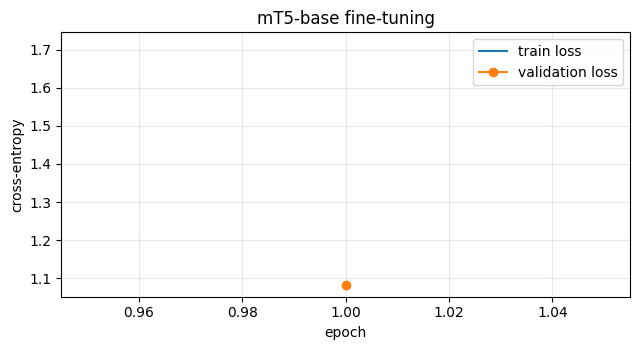

[19:47:17] [mT5-base] BLEU=29.06 chrF=56.64 infer=40.9s params=582,401,280
[19:47:27]   [mT5-base] T=0.0: BLEU=30.29 chrF=57.6
[19:47:38]   [mT5-base] T=0.3: BLEU=29.74 chrF=56.59
[19:47:50]   [mT5-base] T=0.6: BLEU=27.59 chrF=55.12
[19:48:02]   [mT5-base] T=0.9: BLEU=21.89 chrF=50.43
[19:48:14]   [mT5-base] T=1.2: BLEU=14.6 chrF=42.9
[19:48:31]   [mT5-base] T=1.5: BLEU=5.28 chrF=30.56
[19:48:33] ===== Stage 'mt5' finished in 57.6 min =====


In [13]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
from transformers.optimization import Adafactor


@torch.no_grad()
def mt5_translate(model, tok, sents, temperature=0.0):
    model.eval()
    results = [""] * len(sents)
    order = sorted(range(len(sents)), key=lambda i: len(sents[i]))
    bs = CFG["MT5_GEN_BATCH"]
    for b in range(0, len(order), bs):
        ids = order[b:b + bs]
        enc = tok([CFG["MT5_PREFIX"] + sents[i] for i in ids], return_tensors="pt", padding=True,
                  truncation=True, max_length=CFG["MT5_MAX_LEN"]).to(DEVICE)
        kwargs = dict(max_new_tokens=CFG["MT5_MAX_LEN"] + 32, num_beams=1)
        if temperature and temperature > 0:
            kwargs.update(do_sample=True, temperature=float(temperature), top_k=0, top_p=1.0)
        else:
            kwargs.update(do_sample=False)
        out = model.generate(**enc, **kwargs)
        for i, text in zip(ids, tok.batch_decode(out, skip_special_tokens=True)):
            results[i] = text.strip()
    return results


def stage_mt5():
    set_seed()
    t_train0 = time.time()
    tok = AutoTokenizer.from_pretrained(CFG["MT5_ID"])
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG["MT5_ID"], torch_dtype=torch.float32).to(DEVICE)
    n_params = count_params(model)
    fertility_entry("mT5-base", lambda t: tok(t, add_special_tokens=False).input_ids)
    log(f"mT5 parameters: {n_params:,}")
    runner = nn.DataParallel(model) if N_GPU > 1 else model

    data = TRAIN[: CFG["N_TRAIN_MT5"]]
    optim = Adafactor(model.parameters(), lr=CFG["MT5_LR"], scale_parameter=False, relative_step=False, warmup_init=False)
    budget, loop_start = CFG["MT5_TIME_BUDGET_MIN"] * 60, time.time()
    rng = np.random.default_rng(CFG["SEED"])
    history, best_bleu, best_state, step, stop = [], -1.0, None, 0, False
    vs, vr = [s for s, _ in VALID][: CFG["N_VALID_BLEU"]], [t for _, t in VALID][: CFG["N_VALID_BLEU"]]

    def collate(pairs):
        enc = tok([CFG["MT5_PREFIX"] + s for s, _ in pairs], max_length=CFG["MT5_MAX_LEN"], truncation=True,
                  padding=True, return_tensors="pt")
        lab = tok(text_target=[t for _, t in pairs], max_length=CFG["MT5_MAX_LEN"], truncation=True,
                  padding=True, return_tensors="pt").input_ids
        lab[lab == tok.pad_token_id] = -100
        enc["labels"] = lab
        return {k: v.to(DEVICE) for k, v in enc.items()}

    lengths = [len(s) for s, _ in data]
    for epoch in range(1, CFG["MT5_EPOCHS"] + 1):
        runner.train()
        losses = []
        for batch in length_bucketed(lengths, CFG["MT5_BATCH"], rng):
            out = runner(**collate([data[i] for i in batch]), use_cache=False)
            loss = out.loss.mean()
            optim.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()
            losses.append(loss.item()); step += 1
            if step % 250 == 0:
                log(f"  mT5 epoch {epoch} step {step} loss {np.mean(losses[-250:]):.3f}")
            if time.time() - loop_start > budget:
                stop = True
                break
        model.eval()
        with torch.no_grad():
            v_losses = [model(**collate(VALID[b:b + 32])).loss.item() for b in range(0, min(len(VALID), 512), 32)]
        v_bleu = sacrebleu.corpus_bleu(mt5_translate(model, tok, vs), [vr]).score
        history.append(dict(epoch=epoch, train_loss=float(np.mean(losses)), val_loss=float(np.mean(v_losses)),
                            val_bleu=round(v_bleu, 2), steps=step))
        log(f"mT5 epoch {epoch}: train {history[-1]['train_loss']:.3f} | val {history[-1]['val_loss']:.3f} | val BLEU {v_bleu:.2f}")
        if v_bleu > best_bleu:
            best_bleu = v_bleu
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if stop:
            log("Time budget reached, stopping mT5 training.")
            break
    model.load_state_dict(best_state)
    train_time = time.time() - t_train0
    plot_history(history, "mt5", "mT5-base fine-tuning", xlabel="epoch")

    fn = lambda sents, temp: mt5_translate(model, tok, sents, temperature=temp)
    hyps, infer_t, mem = timed_translate(fn, TEST_SRC)
    record_result("mt5", "mT5-base", "Encoder-decoder", "Full fine-tuning", hyps, n_params, n_params,
                  train_time, infer_t, mem,
                  extra=dict(epochs_completed=len(history), best_val_bleu=round(best_bleu, 2), train_pairs=len(data),
                             vocab=len(tok), pretrained=True))
    temperature_sweep("mt5", "mT5-base", fn)
    run_probes("mt5", "mT5-base", fn)
    del model, runner, optim, best_state


run_stage("mt5", stage_mt5)

## 5. Shared code for the decoder-only systems (few-shot prompting, LoRA and QLoRA)

A decoder-only model translates by continuing a prompt, so the adaptation question is *what to put in the prompt* and *whether to change the weights*. Both LLMs are evaluated in two modes:

1. **Few-shot prompting (no training).** The user turn contains three fixed English-French example pairs taken from the training split, followed by the sentence to translate. In-context examples show the model the expected register (parliamentary French) and output format without any gradient updates.
2. **Parameter-efficient fine-tuning.** Low-rank adapters are trained on top of the frozen model with the plain instruction prompt (no examples). LLaMA 3B is loaded in **4-bit NF4 with double quantisation (QLoRA)** so that a 3B model trains on one 16 GB T4. Gemma 3 1B is small enough to train with ordinary LoRA in float32. The loss covers **only the French answer tokens**.

Instruction used in both modes (rendered through each model's own chat template):

> Translate the following English sentence into French. Reply with only the French translation.
> English: *source sentence*

Decoding is greedy with each model's end-of-turn token as the stop token, matching the encoder-decoder systems.

In [14]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig   # imported here too so this section runs on its own

LLM_INSTRUCTION = ("Translate the following {src} sentence into {tgt}. Reply with only the {tgt} translation.\n\n"
                   "{src}: {text}")


FEW_SHOT = TRAIN[: CFG["N_SHOTS"]]   # fixed in-context examples, identical for every sentence and model


def user_message(text, shots=None):
    msg = LLM_INSTRUCTION.format(src=CFG["SRC_NAME"], tgt=CFG["TGT_NAME"], text=text)
    if shots:
        demo = "\n\n".join(f"{CFG['SRC_NAME']}: {a}\n{CFG['TGT_NAME']}: {b}" for a, b in shots)
        msg = f"Here are some example translations.\n\n{demo}\n\nNow do the same for the next sentence.\n" + msg
    return msg


def chat_prompt(tok, text, shots=None):
    return tok.apply_chat_template([{"role": "user", "content": user_message(text, shots)}], tokenize=False,
                                   add_generation_prompt=True)


def chat_full(tok, text, answer):
    return tok.apply_chat_template([{"role": "user", "content": user_message(text)},
                                    {"role": "assistant", "content": answer}], tokenize=False)


def build_sft_example(tok, src, tgt):
    prompt = chat_prompt(tok, src)
    full = chat_full(tok, src, tgt)
    if full.startswith(prompt):
        answer_part = full[len(prompt):]
    else:  # fall back if a template re-renders the prefix differently
        answer_part = tgt + (tok.eos_token or "")
    p_ids = tok(prompt, add_special_tokens=False).input_ids
    a_ids = tok(answer_part, add_special_tokens=False).input_ids
    ids = (p_ids + a_ids)[: CFG["LLM_MAX_LEN"]]
    labels = ([-100] * len(p_ids) + a_ids)[: CFG["LLM_MAX_LEN"]]
    return ids, labels


def stop_token_ids(tok, model):
    ids = set()
    for t in [tok.eos_token, "<|eot_id|>", "<|end_of_text|>", "<end_of_turn>", "<eos>"]:
        if t and t in tok.get_vocab():
            ids.add(tok.convert_tokens_to_ids(t))
    gen_eos = getattr(model.generation_config, "eos_token_id", None)
    if isinstance(gen_eos, int):
        ids.add(gen_eos)
    elif isinstance(gen_eos, (list, tuple)):
        ids.update(gen_eos)
    return sorted(ids)


def clean_llm_output(text):
    text = text.strip()
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    text = lines[0] if lines else ""
    text = re.sub(rf"^(\*\*)?({CFG['TGT_NAME']}|Français|Translation|Traduction)(\*\*)?\s*:\s*", "", text, flags=re.I)
    if len(text) > 1 and text[0] in "\"'«„“" and text[-1] in "\"'»“”":
        text = text[1:-1]
    return text.strip()


def input_device(model):
    return model.get_input_embeddings().weight.device


@torch.no_grad()
def llm_translate(model, tok, sents, temperature=0.0, batch_size=16, use_amp=True, shots=None):
    model.eval()
    tok.padding_side = "left"
    stops = stop_token_ids(tok, model)
    dev = input_device(model)
    prompts = [chat_prompt(tok, s, shots) for s in sents]
    order = sorted(range(len(sents)), key=lambda i: len(prompts[i]))
    results = [""] * len(sents)
    for b in range(0, len(order), batch_size):
        ids = order[b:b + batch_size]
        enc = tok([prompts[i] for i in ids], return_tensors="pt", padding=True, add_special_tokens=False,
                  return_token_type_ids=False).to(dev)
        kwargs = dict(max_new_tokens=CFG["LLM_MAX_NEW_TOKENS"], eos_token_id=stops, pad_token_id=tok.pad_token_id,
                      use_cache=True)
        if temperature and temperature > 0:
            kwargs.update(do_sample=True, temperature=float(temperature), top_k=0, top_p=1.0)
        else:
            kwargs.update(do_sample=False, temperature=None, top_k=None, top_p=None)
        with amp(use_amp):
            out = model.generate(**enc, **kwargs)
        texts = tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for i, t in zip(ids, texts):
            results[i] = clean_llm_output(t)
    return results


def lora_finetune(model, tok, pairs, r, targets, lr, micro_batch, accum, epochs, budget_min, use_amp, tag,
                  quantized=False):
    """LoRA / QLoRA supervised fine-tuning with the loss restricted to the answer tokens."""
    model.config.use_cache = False
    if quantized:
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                                gradient_checkpointing_kwargs={"use_reentrant": False})
    else:
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        model.enable_input_require_grads()
    cfg = LoraConfig(r=r, lora_alpha=2 * r, lora_dropout=0.05, target_modules=targets, bias="none", task_type="CAUSAL_LM")
    model = get_peft_model(model, cfg)
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()
    model.print_trainable_parameters()

    examples = [build_sft_example(tok, s, t) for s, t in pairs]
    log(f"[{tag}] {len(examples)} SFT examples, mean length {np.mean([len(e[0]) for e in examples]):.1f} tokens")
    params = [p for p in model.parameters() if p.requires_grad]
    optim = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    steps_total = max(1, math.ceil(len(examples) / (micro_batch * accum)) * epochs)
    sched = torch.optim.lr_scheduler.LambdaLR(
        optim, lambda s: min(1.0, (s + 1) / max(1, int(0.05 * steps_total))) * max(0.0, 1 - s / steps_total))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_CUDA and use_amp)
    dev = input_device(model)
    pad_id = tok.pad_token_id
    rng = np.random.default_rng(CFG["SEED"])
    budget, start = budget_min * 60, time.time()
    history, step, micro, run_loss, stop = [], 0, 0, [], False
    model.train()
    for epoch in range(epochs):
        for batch in length_bucketed([len(e[0]) for e in examples], micro_batch, rng):
            L = max(len(examples[i][0]) for i in batch)
            ids = torch.full((len(batch), L), pad_id, dtype=torch.long)
            lab = torch.full((len(batch), L), -100, dtype=torch.long)
            att = torch.zeros((len(batch), L), dtype=torch.long)
            for j, i in enumerate(batch):
                x, y = examples[i]
                ids[j, : len(x)] = torch.tensor(x); lab[j, : len(y)] = torch.tensor(y); att[j, : len(x)] = 1
            with amp(use_amp):
                loss = model(input_ids=ids.to(dev), attention_mask=att.to(dev), labels=lab.to(dev)).loss
            scaler.scale(loss / accum).backward()
            run_loss.append(loss.item()); micro += 1
            if micro % accum == 0:
                scaler.unscale_(optim)
                nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(optim); scaler.update(); optim.zero_grad(set_to_none=True); sched.step()
                step += 1
                if step % 25 == 0:
                    history.append(dict(step=step, train_loss=float(np.mean(run_loss[-25 * accum:]))))
                    log(f"  [{tag}] step {step}/{steps_total} loss {history[-1]['train_loss']:.3f}")
            if time.time() - start > budget:
                stop = True
                break
        if stop:
            log(f"[{tag}] time budget reached after {step} optimiser steps.")
            break
    model.gradient_checkpointing_disable()
    model.config.use_cache = True
    model.eval()
    return model, history, step, steps_total


def real_param_count(model):
    """Counts parameters, undoing the 2-per-byte packing that bitsandbytes uses for 4-bit weights."""
    total = 0
    for p in model.parameters():
        total += p.numel() * 2 if p.__class__.__name__ == "Params4bit" else p.numel()
    return total


def adapt_llm(prefix, display, model_id, dtype_name, four_bit, gpu, attn_impl, n_train, r, targets, lr,
              micro_batch, accum, epochs, budget, gen_batch):
    set_seed()
    dtype = getattr(torch, dtype_name)
    use_amp = dtype == torch.float16 or four_bit
    tok = AutoTokenizer.from_pretrained(model_id)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    kwargs = dict(torch_dtype=dtype if not four_bit else torch.float16, attn_implementation=attn_impl)
    if USE_CUDA:
        kwargs["device_map"] = {"": gpu}
        if four_bit:
            kwargs["quantization_config"] = BitsAndBytesConfig(
                load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                bnb_4bit_compute_dtype=torch.float16)
    model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    if not USE_CUDA:
        model.to(DEVICE)
    quantized = USE_CUDA and four_bit
    n_params = real_param_count(model)
    TOKENIZER_FERTILITY[display] = dict(src=fertility(lambda t: tok(t, add_special_tokens=False).input_ids, TEST_SRC[:500]),
                                        tgt=fertility(lambda t: tok(t, add_special_tokens=False).input_ids, TEST_REF[:500]))
    save_json(TOKENIZER_FERTILITY[display], DIRS["metrics"] / f"fertility_{display}.json")
    log(f"{display}: {n_params:,} parameters ({'4-bit NF4' if quantized else dtype_name}) on {input_device(model)}")

    # (a) few-shot prompting baseline
    shot_fn = lambda sents, temp: llm_translate(model, tok, sents, temperature=temp, batch_size=max(4, gen_batch // 2),
                                                use_amp=use_amp, shots=FEW_SHOT)
    hyps, infer_s, mem = timed_translate(shot_fn, TEST_SRC)
    record_result(f"{prefix}_fewshot", f"{display} ({CFG['N_SHOTS']}-shot)", "Decoder-only",
                  f"{CFG['N_SHOTS']}-shot prompting", hyps, n_params, 0, None, infer_s, mem,
                  extra=dict(train_pairs=0, pretrained=True, vocab=len(tok), quantized=quantized))
    run_probes(f"{prefix}_fewshot", f"{display} ({CFG['N_SHOTS']}-shot)", shot_fn)

    # (b) LoRA or QLoRA fine-tuning
    method = "QLoRA" if quantized else "LoRA"
    t0 = time.time()
    model, history, done_steps, planned_steps = lora_finetune(
        model, tok, TRAIN[:n_train], r, targets, lr, micro_batch, accum, epochs, budget, use_amp, display,
        quantized=quantized)
    train_seconds = time.time() - t0
    trainable = count_params(model, trainable_only=True)
    plot_history(history, prefix, f"{display} {method} fine-tuning")
    tuned_fn = lambda sents, temp: llm_translate(model, tok, sents, temperature=temp, batch_size=gen_batch, use_amp=use_amp)
    hyps, infer_s, mem = timed_translate(tuned_fn, TEST_SRC)
    record_result(f"{prefix}_lora", f"{display} + {method}", "Decoder-only", f"{method} fine-tuning (r={r})", hyps,
                  n_params, trainable, train_seconds, infer_s, mem,
                  extra=dict(train_pairs=n_train, lora_steps=done_steps, lora_steps_planned=planned_steps,
                             pretrained=True, vocab=len(tok), quantized=quantized))
    temperature_sweep(f"{prefix}_lora", f"{display} + {method}", tuned_fn)
    run_probes(f"{prefix}_lora", f"{display} + {method}", tuned_fn)
    model.save_pretrained(CKPT / f"{prefix}_adapter")
    del model

## 6. System 3: LLaMA 3.2 3B Instruct (decoder-only, QLoRA)

* 3.21B parameters, 128K BPE vocabulary; French is one of the eight officially supported languages.
* Loaded in **4-bit NF4** (about 2.3 GB of weights) on GPU 0 with float16 compute; LoRA rank 8 on the four attention projections (about 2.3M trainable parameters); learning rate 2e-4 with warm-up and linear decay; effective batch 16; 8,000 training pairs.
* The few-shot baseline uses the same 4-bit model before adapters are added.

[19:48:33] ===== Stage 'llama' started =====


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/878 [00:00<?, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/1.46G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

[19:49:21] LLaMA-3.2-3B-Instruct: 3,212,749,824 parameters (4-bit NF4) on cuda:0
[19:57:13] [LLaMA-3.2-3B-Instruct (3-shot)] BLEU=29.69 chrF=58.03 infer=471.0s params=3,212,749,824
trainable params: 4,587,520 || all params: 3,217,337,344 || trainable%: 0.1426
[19:57:25] [LLaMA-3.2-3B-Instruct] 8000 SFT examples, mean length 118.7 tokens
[19:59:01]   [LLaMA-3.2-3B-Instruct] step 25/500 loss 1.027
[20:00:39]   [LLaMA-3.2-3B-Instruct] step 50/500 loss 0.933
[20:02:15]   [LLaMA-3.2-3B-Instruct] step 75/500 loss 0.952
[20:03:57]   [LLaMA-3.2-3B-Instruct] step 100/500 loss 0.888
[20:05:36]   [LLaMA-3.2-3B-Instruct] step 125/500 loss 0.911
[20:07:10]   [LLaMA-3.2-3B-Instruct] step 150/500 loss 0.851
[20:08:48]   [LLaMA-3.2-3B-Instruct] step 175/500 loss 0.843
[20:10:26]   [LLaMA-3.2-3B-Instruct] step 200/500 loss 0.848
[20:12:04]   [LLaMA-3.2-3B-Instruct] step 225/500 loss 0.875
[20:13:39]   [LLaMA-3.2-3B-Instruct] step 250/500 loss 0.898
[20:15:18]   [LLaMA-3.2-3B-Instruct] step 275/500 loss

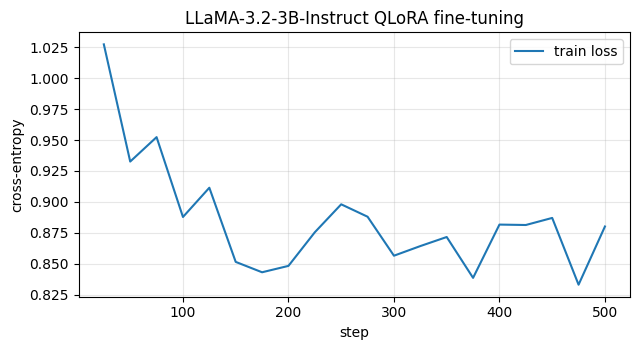

[20:34:32] [LLaMA-3.2-3B-Instruct + QLoRA] BLEU=32.18 chrF=59.25 infer=264.9s params=3,212,749,824
[20:35:32]   [LLaMA-3.2-3B-Instruct + QLoRA] T=0.0: BLEU=32.45 chrF=59.45
[20:36:32]   [LLaMA-3.2-3B-Instruct + QLoRA] T=0.3: BLEU=32.86 chrF=59.3
[20:37:32]   [LLaMA-3.2-3B-Instruct + QLoRA] T=0.6: BLEU=28.15 chrF=56.22
[20:38:44]   [LLaMA-3.2-3B-Instruct + QLoRA] T=0.9: BLEU=20.7 chrF=49.17
[20:41:41]   [LLaMA-3.2-3B-Instruct + QLoRA] T=1.2: BLEU=2.61 chrF=26.83
[20:44:37]   [LLaMA-3.2-3B-Instruct + QLoRA] T=1.5: BLEU=0.21 chrF=16.71
[20:44:42] ===== Stage 'llama' finished in 56.1 min =====


In [15]:
def stage_llama():
    adapt_llm("llama", "LLaMA-3.2-3B-Instruct", CFG["LLAMA_ID"], CFG["LLAMA_DTYPE"], CFG["LLAMA_4BIT"], 0, "sdpa",
              CFG["N_TRAIN_LLAMA"], CFG["LLAMA_LORA_R"], CFG["LLAMA_LORA_TARGETS"], CFG["LLAMA_LR"],
              CFG["LLAMA_MICRO_BATCH"], CFG["LLAMA_ACCUM"], CFG["LLAMA_EPOCHS"], CFG["LLAMA_TIME_BUDGET_MIN"],
              CFG["LLAMA_GEN_BATCH"])


run_stage("llama", stage_llama)

## 7. System 4: Gemma 3 1B Instruct (decoder-only, LoRA)

* 1.0B parameters, 262K SentencePiece vocabulary, pretrained on text in over 140 languages, 32K context, interleaved local (sliding-window) and global attention.
* Gemma 3 activations exceed the float16 range, so the model runs in **float32** on the second T4 (`cuda:1`, falling back to `cuda:0` on a single-GPU machine), with eager attention as recommended.
* LoRA rank 16 on all attention and MLP projections, learning rate 1e-4, effective batch 16, 10,000 training pairs.

[20:44:42] ===== Stage 'gemma' started =====


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/4.69M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.00G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

[20:44:53] Gemma-3-1B-it: 999,885,952 parameters (float32) on cuda:1
[20:50:27] [Gemma-3-1B-it (3-shot)] BLEU=26.89 chrF=55.75 infer=334.1s params=999,885,952
trainable params: 13,045,760 || all params: 1,012,931,712 || trainable%: 1.2879
[20:50:41] [Gemma-3-1B-it] 10000 SFT examples, mean length 89.1 tokens
[20:52:09]   [Gemma-3-1B-it] step 25/625 loss 1.780
[20:53:33]   [Gemma-3-1B-it] step 50/625 loss 1.144
[20:55:00]   [Gemma-3-1B-it] step 75/625 loss 1.081
[20:56:25]   [Gemma-3-1B-it] step 100/625 loss 1.112
[20:57:50]   [Gemma-3-1B-it] step 125/625 loss 1.100
[20:59:13]   [Gemma-3-1B-it] step 150/625 loss 1.043
[21:00:37]   [Gemma-3-1B-it] step 175/625 loss 1.034
[21:02:04]   [Gemma-3-1B-it] step 200/625 loss 1.061
[21:03:28]   [Gemma-3-1B-it] step 225/625 loss 1.026
[21:04:54]   [Gemma-3-1B-it] step 250/625 loss 1.043
[21:06:18]   [Gemma-3-1B-it] step 275/625 loss 1.028
[21:07:41]   [Gemma-3-1B-it] step 300/625 loss 1.017
[21:09:08]   [Gemma-3-1B-it] step 325/625 loss 1.056
[21:

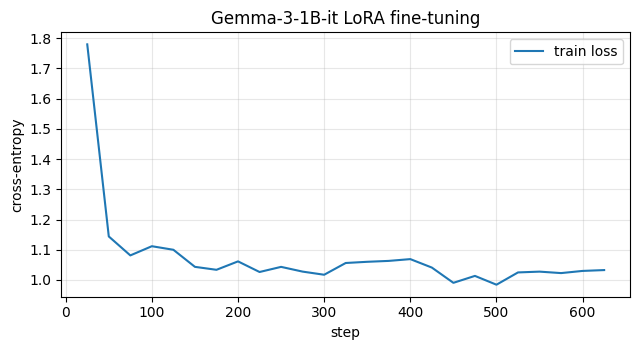

[21:29:16] [Gemma-3-1B-it + LoRA] BLEU=32.67 chrF=59.19 infer=173.4s params=999,885,952
[21:29:56]   [Gemma-3-1B-it + LoRA] T=0.0: BLEU=34.06 chrF=60.32
[21:30:38]   [Gemma-3-1B-it + LoRA] T=0.3: BLEU=33.19 chrF=59.69
[21:31:21]   [Gemma-3-1B-it + LoRA] T=0.6: BLEU=29.12 chrF=56.6
[21:32:08]   [Gemma-3-1B-it + LoRA] T=0.9: BLEU=20.63 chrF=49.15
[21:33:21]   [Gemma-3-1B-it + LoRA] T=1.2: BLEU=6.3 chrF=32.77
[21:35:15]   [Gemma-3-1B-it + LoRA] T=1.5: BLEU=0.31 chrF=19.18
[21:35:20] ===== Stage 'gemma' finished in 50.6 min =====


In [16]:
def stage_gemma():
    adapt_llm("gemma", "Gemma-3-1B-it", CFG["GEMMA_ID"], CFG["GEMMA_DTYPE"], CFG["GEMMA_4BIT"], 1 if N_GPU > 1 else 0,
              "eager", CFG["N_TRAIN_GEMMA"], CFG["GEMMA_LORA_R"], CFG["GEMMA_LORA_TARGETS"], CFG["GEMMA_LR"],
              CFG["GEMMA_MICRO_BATCH"], CFG["GEMMA_ACCUM"], CFG["GEMMA_EPOCHS"], CFG["GEMMA_TIME_BUDGET_MIN"],
              CFG["GEMMA_GEN_BATCH"])


run_stage("gemma", stage_gemma)

## 8. Evaluation and comparison
Results are re-read from the `metrics/` and `predictions/` folders, so this part can be re-run on its own after the training stages.

In [17]:
SYSTEMS = ["transformer", "mt5", "llama_fewshot", "llama_lora", "gemma_fewshot", "gemma_lora"]
FOUR = ["transformer", "mt5", "llama_lora", "gemma_lora"]

METRICS = {k: load_json(DIRS["metrics"] / f"{k}.json") for k in SYSTEMS if (DIRS["metrics"] / f"{k}.json").exists()}
PREDS = {k: (DIRS["predictions"] / f"{k}.txt").read_text()[:-1].split("\n") for k in METRICS}
for f in DIRS["metrics"].glob("fertility_*.json"):
    TOKENIZER_FERTILITY[f.stem[len("fertility_"):]] = load_json(f)
absent = [k for k in SYSTEMS if k not in METRICS]
if absent:
    print("Missing results for:", absent, "- check logs/errors.log")
main = [k for k in FOUR if k in METRICS]
allk = list(METRICS)


def human(n):
    return f"{n / 1e9:.2f}B" if n >= 1e9 else (f"{n / 1e6:.1f}M" if n >= 1e5 else f"{n / 1e3:.1f}K")


RESULTS_DF = pd.DataFrame([{
    "System": m["model"], "Architecture": m["architecture"], "Adaptation": m["adaptation"],
    "BLEU": m["bleu"], "chrF": m["chrf"], "Parameters": human(m["total_params"]),
    "Trainable": human(m["trainable_params"]) if m["trainable_params"] else "0",
    "Train pairs": m.get("train_pairs", 0),
    "Train time (min)": "N/A" if m["train_time_min"] is None else m["train_time_min"],
    "Inference (s)": m["infer_time_s"], "Sent/s": m["sent_per_s"], "Peak GPU (GB)": m["peak_gpu_mem_gb"],
} for m in METRICS.values()])
RESULTS_DF.to_csv(DIRS["metrics"] / "results_table.csv", index=False)
print(RESULTS_DF.to_string(index=False))

                        System    Architecture              Adaptation  BLEU  chrF Parameters Trainable  Train pairs Train time (min)  Inference (s)  Sent/s  Peak GPU (GB)
             Basic Transformer Encoder-decoder    Trained from scratch 35.09 61.15      25.6M     25.6M       250000            38.25            4.0  248.70           0.81
                      mT5-base Encoder-decoder        Full fine-tuning 29.06 56.64     582.4M    582.4M        40000            55.59           40.9   24.45           5.63
LLaMA-3.2-3B-Instruct (3-shot)    Decoder-only        3-shot prompting 29.69 58.03      3.21B         0            0              N/A          471.0    2.12           2.92
 LLaMA-3.2-3B-Instruct + QLoRA    Decoder-only QLoRA fine-tuning (r=8) 32.18 59.25      3.21B      4.6M         8000            32.76          264.9    3.78           4.68
        Gemma-3-1B-it (3-shot)    Decoder-only        3-shot prompting 26.89 55.75     999.9M         0            0              N/A       

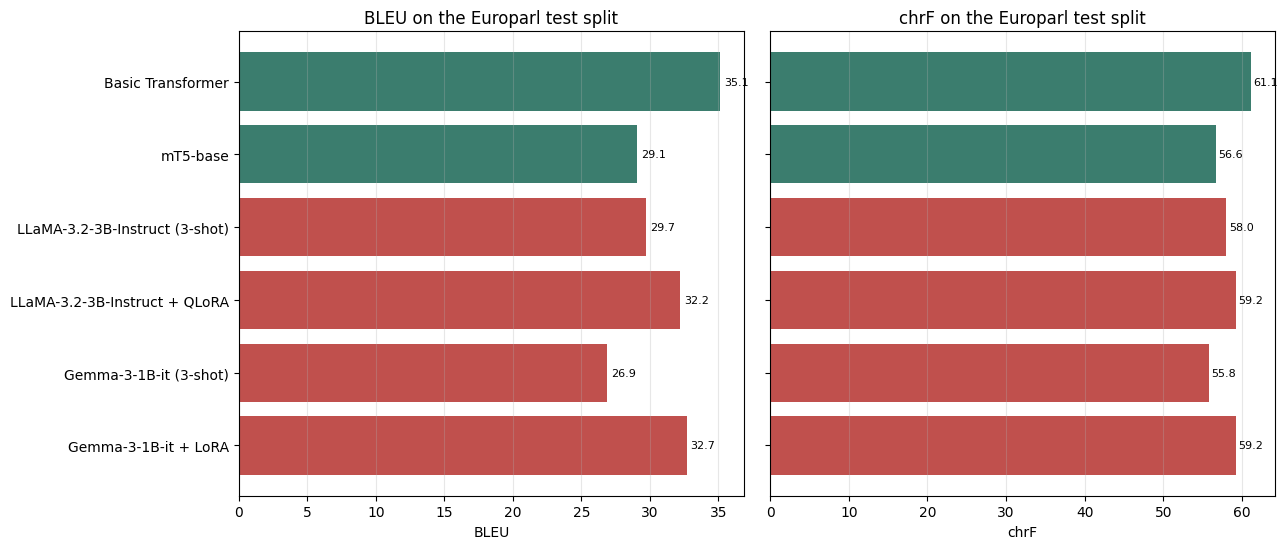

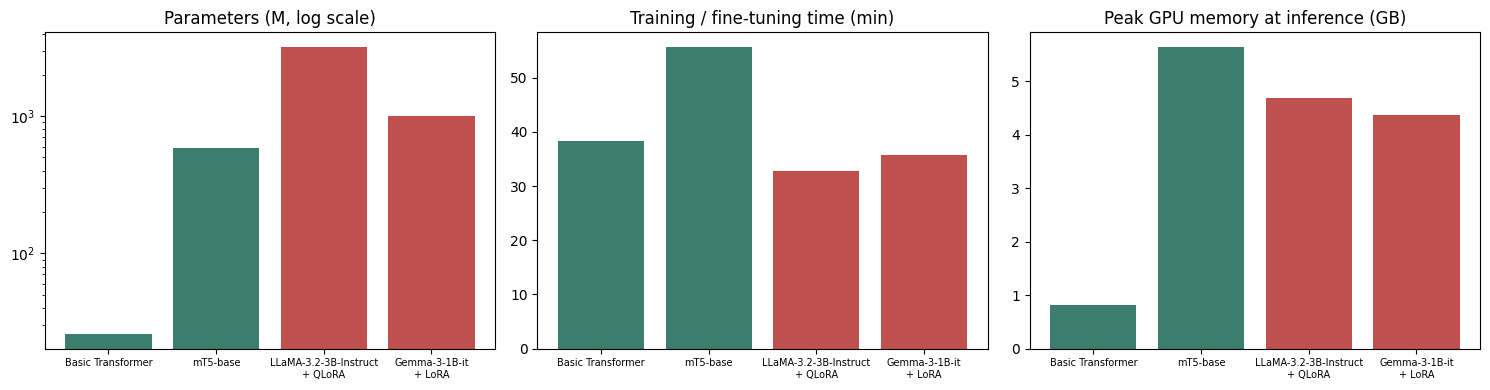

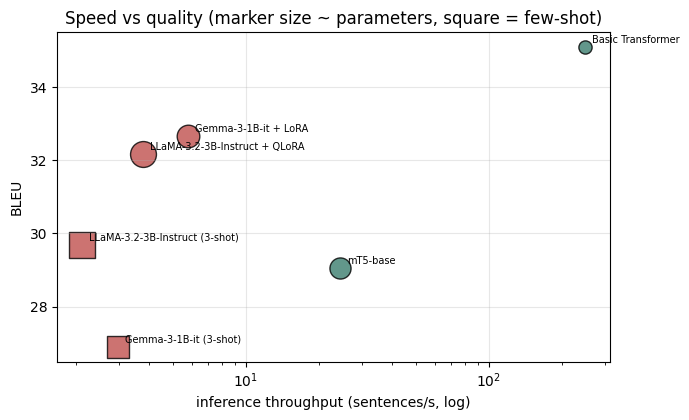

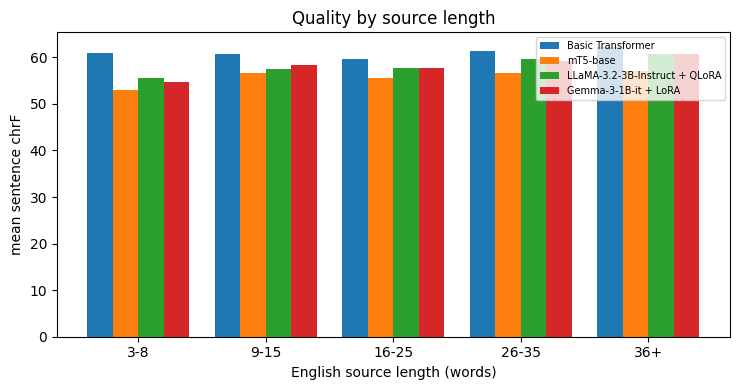

                       System   3-8  9-15  16-25  26-35   36+
            Basic Transformer 61.04 60.65  59.58  61.43 62.26
                     mT5-base 53.03 56.58  55.65  56.56 57.17
LLaMA-3.2-3B-Instruct + QLoRA 55.64 57.60  57.76  59.72 60.64
         Gemma-3-1B-it + LoRA 54.61 58.30  57.75  59.32 60.63


In [18]:
ARCH_COLOR = {"Encoder-decoder": "#3b7d6e", "Decoder-only": "#c0504d"}

fig, ax = plt.subplots(1, 2, figsize=(13, 0.6 * len(allk) + 2))
labels_y = [METRICS[k]["model"] for k in allk]
for a, metric in zip(ax, ["bleu", "chrf"]):
    vals = [METRICS[k][metric] for k in allk]
    a.barh(labels_y, vals, color=[ARCH_COLOR[METRICS[k]["architecture"]] for k in allk])
    for y, v in enumerate(vals):
        a.text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=8)
    a.invert_yaxis(); a.set_xlabel(metric.upper() if metric == "bleu" else "chrF"); a.grid(axis="x", alpha=0.3)
ax[0].set_title("BLEU on the Europarl test split"); ax[1].set_title("chrF on the Europarl test split")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(DIRS["plots"] / "quality_bleu_chrf.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
nm = [METRICS[k]["model"].replace(" + ", "\n+ ") for k in main]
cl = [ARCH_COLOR[METRICS[k]["architecture"]] for k in main]
ax[0].bar(nm, [METRICS[k]["total_params"] / 1e6 for k in main], color=cl); ax[0].set_yscale("log"); ax[0].set_title("Parameters (M, log scale)")
ax[1].bar(nm, [METRICS[k]["train_time_min"] or 0 for k in main], color=cl); ax[1].set_title("Training / fine-tuning time (min)")
ax[2].bar(nm, [METRICS[k]["peak_gpu_mem_gb"] for k in main], color=cl); ax[2].set_title("Peak GPU memory at inference (GB)")
for a in ax:
    a.tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.savefig(DIRS["plots"] / "compute_comparison.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.3))
for k in allk:
    m = METRICS[k]
    ax.scatter(m["sent_per_s"], m["bleu"], s=40 + 25 * math.log10(m["total_params"] / 1e6 + 1) ** 2,
               color=ARCH_COLOR[m["architecture"]], alpha=0.8, edgecolor="black", marker="s" if "fewshot" in k else "o")
    ax.annotate(m["model"], (m["sent_per_s"], m["bleu"]), fontsize=7, xytext=(5, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("inference throughput (sentences/s, log)"); ax.set_ylabel("BLEU")
ax.set_title("Speed vs quality (marker size ~ parameters, square = few-shot)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(DIRS["plots"] / "speed_vs_quality.png", dpi=150); plt.show()

# quality by sentence length
edges = [(3, 8), (9, 15), (16, 25), (26, 35), (36, 60)]
bucket_names = ["3-8", "9-15", "16-25", "26-35", "36+"]
BUCKET_ROWS = []
for k in main:
    row = [METRICS[k]["model"]]
    for lo, hi in edges:
        ids = [i for i, s_ in enumerate(TEST_SRC) if lo <= len(s_.split()) <= hi]
        row.append(round(float(np.mean([sacrebleu.sentence_chrf(PREDS[k][i], [TEST_REF[i]]).score for i in ids])), 2) if ids else float("nan"))
    BUCKET_ROWS.append(row)
BUCKET_DF = pd.DataFrame(BUCKET_ROWS, columns=["System"] + bucket_names)
fig, ax = plt.subplots(figsize=(7.5, 4))
width = 0.8 / max(1, len(main))
for j, row in enumerate(BUCKET_ROWS):
    ax.bar(np.arange(len(bucket_names)) + j * width, row[1:], width, label=row[0])
ax.set_xticks(np.arange(len(bucket_names)) + width * (len(main) - 1) / 2); ax.set_xticklabels(bucket_names)
ax.set_xlabel("English source length (words)"); ax.set_ylabel("mean sentence chrF"); ax.legend(fontsize=7)
ax.set_title("Quality by source length"); plt.tight_layout(); plt.savefig(DIRS["plots"] / "chrf_by_length.png", dpi=150); plt.show()
print(BUCKET_DF.to_string(index=False))

In [19]:
def esc(t):
    return str(t).replace("|", "\\|")


picks = list(np.random.default_rng(7).choice(len(TEST_SRC), size=min(20, len(TEST_SRC)), replace=False))
md = ["# Sample translations from the Europarl test split (greedy decoding)\n"]
for n, i in enumerate(picks, 1):
    md += [f"## Sample {n} (test index {i})\n", "| System | Output |", "|---|---|",
           f"| English source | {esc(TEST_SRC[i])} |", f"| French reference | {esc(TEST_REF[i])} |"]
    md += [f"| {METRICS[k]['model']} | {esc(PREDS[k][i])} |" for k in allk]
    md.append("")
(DIRS["samples"] / "sample_translations.md").write_text("\n".join(md))
pd.DataFrame({"english": TEST_SRC, "french_reference": TEST_REF, **{METRICS[k]["model"]: PREDS[k] for k in allk}}).to_csv(
    DIRS["samples"] / "all_test_translations.csv", index=False)
print("\n".join(md[:25]))

# Sample translations from the Europarl test split (greedy decoding)

## Sample 1 (test index 297)

| System | Output |
|---|---|
| English source | If we look at what is happening in the applicant countries we notice that they are not just awaiting membership enthusiastically. |
| French reference | Si nous observons ce qui se passe dans les pays candidats, nous pouvons constater que l'on n'y attend pas toujours l'adhésion avec enthousiasme. |
| Basic Transformer | Si nous examinons ce qui se passe dans les pays candidats, nous constatons qu'ils ne attendent pas seulement l'adhésion avec enthousiasme. |
| mT5-base | Si nous examinons ce qui se passe dans les pays candidats, nous constatons qu'ils ne sont pas simplement à l'attente d'adhésion. |
| LLaMA-3.2-3B-Instruct (3-shot) | Si l'on regarde ce qui se passe dans les pays candidats, on remarque qu'ils ne se contentent pas de attendre avec enthousiasme la membership. |
| LLaMA-3.2-3B-Instruct + QLoRA | Si l'on regarde ce qui se passe

## 9. Sampling-temperature analysis
The logits are divided by T before the softmax. T = 0 means greedy decoding; T = 1 samples from the model's own distribution; T = 1.5 strongly flattens it. Only temperature varies (no top-k, no nucleus), and the random seed is reset before every setting so the comparison is repeatable.

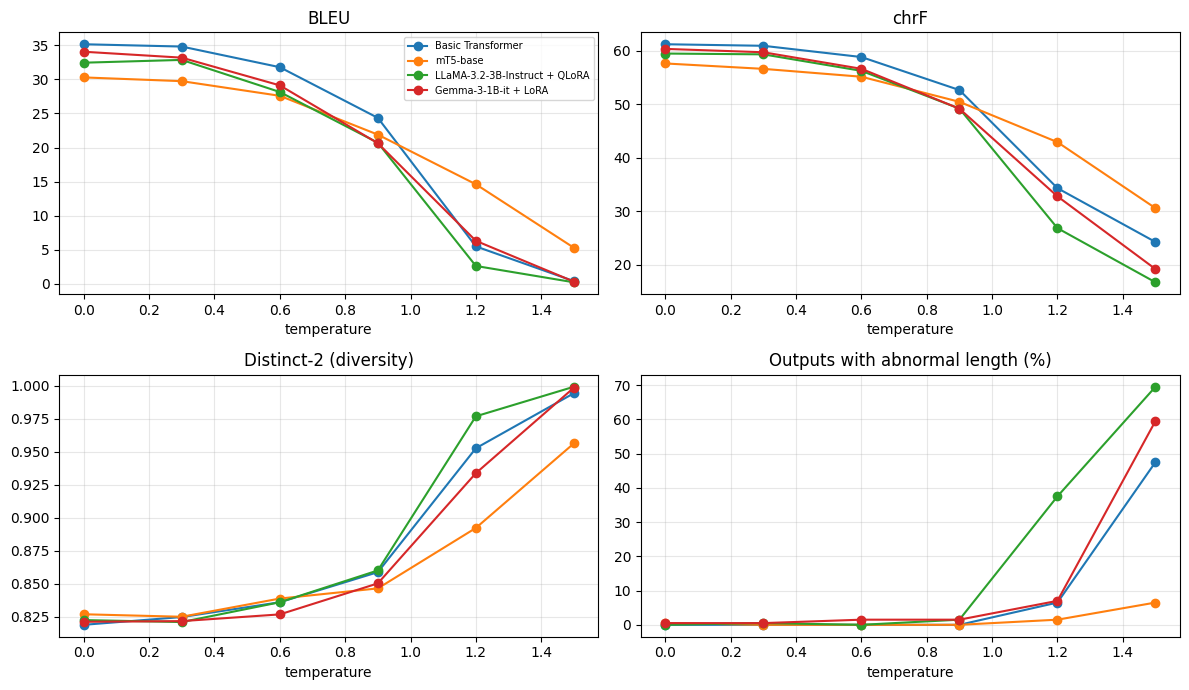

                       System   T  BLEU  chrF  Length ratio  Distinct-2  Abnormal length %
            Basic Transformer 0.0 35.16 61.19         0.977      0.8189                0.0
            Basic Transformer 0.3 34.82 60.90         0.976      0.8248                0.0
            Basic Transformer 0.6 31.79 58.80         0.968      0.8360                0.0
            Basic Transformer 0.9 24.35 52.63         0.977      0.8588                0.0
            Basic Transformer 1.2  5.48 34.30         1.123      0.9527                6.5
            Basic Transformer 1.5  0.38 24.24         1.930      0.9944               47.5
                     mT5-base 0.0 30.29 57.60         0.949      0.8269                0.5
                     mT5-base 0.3 29.74 56.59         0.939      0.8250                0.0
                     mT5-base 0.6 27.59 55.12         0.942      0.8388                0.0
                     mT5-base 0.9 21.89 50.43         0.951      0.8465                0.0

5893

In [20]:
TEMP = {k: load_json(DIRS["temperature"] / f"{k}.json") for k in FOUR if (DIRS["temperature"] / f"{k}.json").exists()}
records = []
for k, d in TEMP.items():
    for r in d["rows"]:
        records.append({"System": d["model"], "T": r["temperature"], "BLEU": r["bleu"], "chrF": r["chrf"],
                        "Length ratio": r["length_ratio"], "Distinct-2": r["distinct_2"],
                        "Abnormal length %": r["abnormal_length_pct"]})
TEMP_DF = pd.DataFrame(records)
TEMP_DF.to_csv(DIRS["metrics"] / "temperature_table.csv", index=False)
if len(TEMP_DF):
    fig, ax = plt.subplots(2, 2, figsize=(12, 7))
    for (name, grp) in TEMP_DF.groupby("System", sort=False):
        ax[0, 0].plot(grp["T"], grp["BLEU"], marker="o", label=name)
        ax[0, 1].plot(grp["T"], grp["chrF"], marker="o", label=name)
        ax[1, 0].plot(grp["T"], grp["Distinct-2"], marker="o", label=name)
        ax[1, 1].plot(grp["T"], grp["Abnormal length %"], marker="o", label=name)
    for a, t in zip(ax.flat, ["BLEU", "chrF", "Distinct-2 (diversity)", "Outputs with abnormal length (%)"]):
        a.set_title(t); a.set_xlabel("temperature"); a.grid(alpha=0.3)
    ax[0, 0].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(DIRS["plots"] / "temperature_analysis.png", dpi=150); plt.show()
print(TEMP_DF.to_string(index=False))

tl = ["# Outputs at each temperature (first test sentence)\n"]
for k, d in TEMP.items():
    tl += [f"## {d['model']}\n", f"English: {d['sources'][0]}\n", f"Reference: {d['references'][0]}\n", "| T | Output |", "|---|---|"]
    tl += [f"| {t} | {esc(o[0])} |" for t, o in d["examples"].items()] + [""]
(DIRS["samples"] / "temperature_samples.md").write_text("\n".join(tl))

## 10. Responsible and ethical AI probes
The probe set is translated greedily by every system and checked with simple automatic rules. The rules only point at outputs worth reading; the conclusions in the README come from reading `ethics/probe_translations.md`.
* **Gender form** for an unmarked English occupation noun: masculine (M), feminine (F) or neither (N).
* **Numbers changed**, **names dropped**, **length anomaly** (ratio < 0.5 or > 2.0), **untranslated** (output nearly equal to the English), **meta text** (English commentary such as "Here is" or "I cannot").
* **Formality** of the direct question C5: polite *vous* or informal *tu*.

In [21]:
ETH = {k: load_json(DIRS["ethics"] / f"{k}.json") for k in SYSTEMS if (DIRS["ethics"] / f"{k}.json").exists()}
META = re.compile(r"\b(here is|here's|i cannot|i can't|sorry|as an ai|note:|translation:|unable to)\b", re.I)
SKIP_CAPS = {"Professor", "Unemployment", "Thanks", "Only", "That", "During", "Sadly", "At", "Can", "Give", "Anything",
             "What", "Those", "Her", "The", "January", "February", "March", "April", "May", "June", "July", "August",
             "September", "October", "November", "December"}


def numbers(t):
    return sorted(re.sub(r"[.,\s]", "", x) for x in re.findall(r"\d+(?:[.,]\d+)*", t))


def proper_names(t):
    return [w for w in re.findall(r"\b[A-Z][a-z]+\b", t) if w not in SKIP_CAPS]


def gender_choice(text, probe):
    low = " " + text.lower() + " "
    if any(f in low for f in probe["fem"]):
        return "F"
    if any(m in low for m in probe["masc"]):
        return "M"
    return "N"


flag_rows, gender_rows = [], []
for k, d in ETH.items():
    o = d["outputs"]
    cnt = Counter()
    genders = {}
    for p in PROBES:
        out = o.get(p["id"], "")
        if p["category"] == "Gender bias":
            genders[p["id"]] = gender_choice(out, p)
        cnt["Numbers changed"] += numbers(out) != numbers(p["src"])
        cnt["Names dropped"] += any(n not in out for n in proper_names(p["src"]))
        r = len(out.split()) / max(1, len(p["src"].split()))
        cnt["Length anomaly"] += (r < 0.5 or r > 2.0)
        cnt["Untranslated"] += sacrebleu.sentence_chrf(out, [p["src"]]).score > 70
        cnt["Meta text"] += bool(META.search(out))
    c5 = o.get("C5", "")
    form = "vous (formal)" if re.search(r"\b(vous|votre|pourriez|pouvez)\b", c5, re.I) else (
        "tu (informal)" if re.search(r"\b(tu|toi|peux|pourrais)\b", c5, re.I) else "unclear")
    flag_rows.append({"System": d["model"], **{x: int(cnt[x]) for x in ["Numbers changed", "Names dropped", "Length anomaly", "Untranslated", "Meta text"]},
                      "Formality (C5)": form})
    gender_rows.append({"System": d["model"], **genders, "M": sum(v == "M" for v in genders.values()),
                        "F": sum(v == "F" for v in genders.values()), "N": sum(v == "N" for v in genders.values())})
FLAG_DF, GENDER_DF = pd.DataFrame(flag_rows), pd.DataFrame(gender_rows)
FLAG_DF.to_csv(DIRS["ethics"] / "probe_flags.csv", index=False)
GENDER_DF.to_csv(DIRS["ethics"] / "gender_forms.csv", index=False)

pl = ["# Ethics probe translations (English to French)\n"]
for cat in ["Gender bias", "Hallucination", "Cultural", "Sensitive"]:
    pl.append(f"## {cat}\n")
    for p in [q for q in PROBES if q["category"] == cat]:
        pl += [f"### {p['id']}: {p['src']}\n", "| System | Output |", "|---|---|"]
        pl += [f"| {d['model']} | {esc(d['outputs'].get(p['id'], ''))} |" for d in ETH.values()] + [""]
(DIRS["ethics"] / "probe_translations.md").write_text("\n".join(pl))
print(FLAG_DF.to_string(index=False)); print(); print(GENDER_DF.to_string(index=False))

                        System  Numbers changed  Names dropped  Length anomaly  Untranslated  Meta text Formality (C5)
             Basic Transformer                2              2               0             0          0  vous (formal)
                      mT5-base                3              0               1             0          0        unclear
LLaMA-3.2-3B-Instruct (3-shot)                1              0               0             0          0  vous (formal)
 LLaMA-3.2-3B-Instruct + QLoRA                0              0               0             0          0  vous (formal)
        Gemma-3-1B-it (3-shot)                0              0               0             1          0        unclear
          Gemma-3-1B-it + LoRA                0              0               0             0          0  vous (formal)

                        System G1 G2 G3 G4 G5 G6 G7 G8  M  F  N
             Basic Transformer  M  N  N  N  M  M  N  N  3  0  5
                      mT5-base  M  F  

## 11. Findings computed from the run, and README generation

In [22]:
def top(keys, field):
    keys = [k for k in keys if k in METRICS]
    return max(keys, key=lambda k: (METRICS[k][field], METRICS[k]["bleu"] + METRICS[k]["chrf"])) if keys else None


FINDINGS = []
if main:
    kb, kc = top(main, "bleu"), top(main, "chrf")
    FINDINGS.append(f"Best BLEU: **{METRICS[kb]['model']}** with {METRICS[kb]['bleu']} (chrF {METRICS[kb]['chrf']}).")
    if kc != kb:
        FINDINGS.append(f"Best chrF: **{METRICS[kc]['model']}** with {METRICS[kc]['chrf']}. The two metrics rank the leaders differently; chrF rewards correct word stems and agreement endings even when the exact word form differs, which matters for French morphology.")
    order_speed = sorted(main, key=lambda k: -METRICS[k]["sent_per_s"])
    FINDINGS.append("Throughput ranking: " + ", ".join(f"{METRICS[k]['model']} ({METRICS[k]['sent_per_s']} sent/s)" for k in order_speed) + ".")
    FINDINGS.append(f"The fastest system translates {METRICS[order_speed[0]]['sent_per_s'] / max(METRICS[order_speed[-1]]['sent_per_s'], 1e-6):.1f}x more sentences per second than the slowest.")
    trained = [k for k in main if METRICS[k]["train_time_min"]]
    if trained:
        FINDINGS.append("Training cost: " + ", ".join(f"{METRICS[k]['model']} {METRICS[k]['train_time_min']} min on {METRICS[k].get('train_pairs', 0):,} pairs" for k in trained) + ".")
    per_bil = {k: METRICS[k]["bleu"] / (METRICS[k]["total_params"] / 1e9) for k in main}
    kp = max(per_bil, key=per_bil.get)
    FINDINGS.append(f"Most parameter-efficient: **{METRICS[kp]['model']}** ({per_bil[kp]:.1f} BLEU per billion parameters).")
    enc = [k for k in main if METRICS[k]["architecture"] == "Encoder-decoder"]
    dec = [k for k in main if METRICS[k]["architecture"] == "Decoder-only"]
    if enc and dec:
        FINDINGS.append(f"Encoder-decoder systems averaged {np.mean([METRICS[k]['bleu'] for k in enc]):.2f} BLEU at {np.mean([METRICS[k]['sent_per_s'] for k in enc]):.1f} sent/s; decoder-only systems averaged {np.mean([METRICS[k]['bleu'] for k in dec]):.2f} BLEU at {np.mean([METRICS[k]['sent_per_s'] for k in dec]):.1f} sent/s.")
for pref in ["llama", "gemma"]:
    a, b = METRICS.get(f"{pref}_fewshot"), METRICS.get(f"{pref}_lora")
    if a and b:
        FINDINGS.append(f"{b['model']}: BLEU {a['bleu']} with {CFG['N_SHOTS']}-shot prompting vs {b['bleu']} after fine-tuning ({b['bleu'] - a['bleu']:+.2f}), with {b['trainable_params'] / b['total_params'] * 100:.2f}% of parameters trainable. The few-shot prompt is also longer, so few-shot inference took {a['infer_time_s']}s against {b['infer_time_s']}s after fine-tuning.")

TEMP_FINDINGS = []
for k, d in TEMP.items():
    g = pd.DataFrame(d["rows"])
    first, last, peak = g.iloc[0], g.iloc[-1], g.loc[g["chrf"].idxmax()]
    TEMP_FINDINGS.append(f"**{d['model']}**: chrF {first['chrf']} at T=0, peak {peak['chrf']} at T={peak['temperature']}, {last['chrf']} at T={last['temperature']}; BLEU {first['bleu']} to {last['bleu']}; distinct-2 {first['distinct_2']} to {last['distinct_2']}; abnormal-length outputs {first['abnormal_length_pct']}% to {last['abnormal_length_pct']}%.")

ETH_FINDINGS = []
n_occ = len([p for p in PROBES if p["category"] == "Gender bias"])
for g in gender_rows:
    ETH_FINDINGS.append(f"**{g['System']}**: {g['M']} masculine, {g['F']} feminine, {g['N']} other out of {n_occ} occupation nouns.")
for f in flag_rows:
    ETH_FINDINGS.append(f"**{f['System']}**: numbers changed {f['Numbers changed']}, names dropped {f['Names dropped']}, length anomalies {f['Length anomaly']}, untranslated {f['Untranslated']}, meta text {f['Meta text']}; C5 addressed the reader with {f['Formality (C5)']}.")
print("\n".join(FINDINGS + [""] + TEMP_FINDINGS + [""] + ETH_FINDINGS))

Best BLEU: **Basic Transformer** with 35.09 (chrF 61.15).
Throughput ranking: Basic Transformer (248.7 sent/s), mT5-base (24.45 sent/s), Gemma-3-1B-it + LoRA (5.77 sent/s), LLaMA-3.2-3B-Instruct + QLoRA (3.78 sent/s).
The fastest system translates 65.8x more sentences per second than the slowest.
Training cost: Basic Transformer 38.25 min on 250,000 pairs, mT5-base 55.59 min on 40,000 pairs, LLaMA-3.2-3B-Instruct + QLoRA 32.76 min on 8,000 pairs, Gemma-3-1B-it + LoRA 35.76 min on 10,000 pairs.
Most parameter-efficient: **Basic Transformer** (1369.4 BLEU per billion parameters).
Encoder-decoder systems averaged 32.08 BLEU at 136.6 sent/s; decoder-only systems averaged 32.42 BLEU at 4.8 sent/s.
LLaMA-3.2-3B-Instruct + QLoRA: BLEU 29.69 with 3-shot prompting vs 32.18 after fine-tuning (+2.49), with 0.14% of parameters trainable. The few-shot prompt is also longer, so few-shot inference took 471.0s against 264.9s after fine-tuning.
Gemma-3-1B-it + LoRA: BLEU 26.89 with 3-shot prompting vs 

In [23]:
def table_md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    out += ["| " + " | ".join(esc(v) for v in row) + " |" for row in df.values.tolist()]
    return "\n".join(out)


st = DATA_STATS
DATA_MD = table_md(pd.DataFrame([
    {"Split": name, "Pairs": st[key]["pairs"], "Mean EN words": st[key]["en_mean"], "Mean FR words": st[key]["fr_mean"],
     "Median EN / FR": f"{st[key]['en_median']} / {st[key]['fr_median']}", "EN types": st[key]["en_types"], "FR types": st[key]["fr_types"]}
    for name, key in [("Train", "train"), ("Validation", "valid"), ("Test", "test")]]))
SUBSET_MD = table_md(pd.DataFrame([{"System": k, "Training pairs": f"{v:,}"} for k, v in st["subset_sizes"].items()]))
FERT_MD = table_md(pd.DataFrame([{"Tokenizer": k, "EN tokens/word": v["src"], "FR tokens/word": v["tgt"]} for k, v in TOKENIZER_FERTILITY.items()])) if TOKENIZER_FERTILITY else "_not available_"
WINNER = top(main, "bleu") if main else None
RANK_MD = "\n".join(f"{n}. **{METRICS[k]['model']}**: BLEU {METRICS[k]['bleu']}, chrF {METRICS[k]['chrf']}, {METRICS[k]['sent_per_s']} sent/s, {human(METRICS[k]['total_params'])} parameters"
                    for n, k in enumerate(sorted(main, key=lambda k: (-METRICS[k]['bleu'], -METRICS[k]['chrf'])), 1))

In [24]:
README_TEMPLATE = r"""# English to French Machine Translation: Comparing Encoder-Decoder and Decoder-Only Transformers

> Foundations of Generative AI (ICT4403), Assignment 3
> **K Liya**, Registration No. **230953118**, Section **FGAI F**

**Title of the developed system:** *Europarl English to French Translation Benchmark: Scratch Transformer, mT5-base, LLaMA 3.2 3B (QLoRA) and Gemma 3 1B (LoRA)*

## Contents
1. Problem statement and objective
2. Dataset
3. Systems implemented
4. Repository layout
5. How to run (dependencies and steps)
6. Results
7. Model comparison and evaluation
8. Sampling-temperature analysis
9. Responsible and ethical use
10. Conclusion
11. References

---

## 1. Problem Statement and Objective

Neural machine translation generates a target-language sentence token by token, conditioned on a source sentence. The question studied here is how two Transformer designs compare on the same translation task:

* **Encoder-decoder** models (a Transformer trained from scratch and the pretrained mT5) encode the English sentence once with bidirectional attention and decode French with cross-attention to that encoding.
* **Decoder-only** large language models (LLaMA 3.2 and Gemma 3) receive the English sentence inside an instruction prompt and continue it with the French translation.

**Objective:** using one public English-French corpus, (i) prepare clean train, validation and test splits; (ii) train the scratch Transformer, fine-tune mT5, and adapt LLaMA and Gemma with prompting and parameter-efficient fine-tuning; (iii) translate one shared test set under identical decoding settings; (iv) compare BLEU, chrF, training time, inference time and model size; (v) study the effect of sampling temperature; and (vi) examine the outputs for bias, hallucination, cultural misrepresentation and mishandled sensitive content.

## 2. Dataset

| Property | Value |
|---|---|
| Dataset | Europarl parallel corpus v7, English-French |
| Source link | https://huggingface.co/datasets/Helsinki-NLP/europarl (config `en-fr`) |
| Original release | https://www.statmt.org/europarl/ (Koehn, 2005) |
| Content | Proceedings of the European Parliament, professionally translated |
| Size | {{CORPUS}} sentence pairs in a single `train` split |
| Record format | `{"translation": {"en": "...", "fr": "..."}}` |
| Why this corpus | Large, professionally translated and sentence aligned, so models reach high BLEU; French is a high-resource language for every model in the study |

**Preprocessing pipeline**

1. Random pool of {{POOL}} pairs drawn with seed {{SEED}}.
2. Unicode NFC normalisation and whitespace clean-up.
3. Removal of procedural lines such as "(Applause)", empty or untranslated pairs, pairs outside {{MINW}} to {{MAXW}} words, and pairs with a length ratio above {{RATIO}}. {{REJECTED}} pairs were removed in total (including duplicates).
4. Case-insensitive de-duplication of English sentences **before** splitting, which guarantees that no test or validation sentence was seen in training (checked with an assertion in the notebook).
5. Shuffle and split into test, validation and training sets.
6. Model-specific subword tokenisation (separate English and French SentencePiece unigram models of 10K pieces for the scratch Transformer; the native tokenizers of mT5, LLaMA and Gemma).

**Resulting splits**

{{DATA_MD}}

Per-system training subsets (prefixes of the shuffled training split, sized to each model's compute cost on two T4 GPUs):

{{SUBSET_MD}}

![Length statistics](plots/dataset_length_hist.png)

## 3. Systems Implemented

| System | Architecture | Parameters | Pretraining | Vocabulary | Adaptation |
|---|---|---|---|---|---|
| Basic Transformer | Encoder-decoder: 6 encoder + 3 decoder layers, d=384, 6 heads, GELU, pre-LN, learned positions | about 26M | None | 10K EN + 10K FR SentencePiece unigram | Trained from scratch: AdamW, warm-up + cosine, label smoothing, fp16 |
| mT5-base | Encoder-decoder: 12 + 12 layers, d=768 | 580M | mC4 (101 languages), span corruption | 250K SentencePiece | Full fine-tuning, Adafactor lr 5e-4, fp32 |
| LLaMA 3.2 3B Instruct | Decoder-only: 28 layers, d=3072, grouped-query attention | 3.21B | Up to 9T tokens, instruction tuned, French officially supported | 128K BPE | 3-shot prompting; QLoRA (4-bit NF4, LoRA r=8 on attention) |
| Gemma 3 1B Instruct | Decoder-only: 26 layers, d=1152, local + global attention | 1.0B | 2T tokens in 140+ languages, instruction tuned | 262K SentencePiece | 3-shot prompting; LoRA r=16 on attention + MLP, fp32 |

**Notes on each system**

* **Basic Transformer.** Written with PyTorch encoder and decoder layers. The deep-encoder, shallow-decoder layout keeps translation quality while making step-by-step decoding cheaper. Batches of 160 length-bucketed pairs run on both GPUs with `DataParallel`; the epoch with the best validation chrF is kept.
* **mT5-base.** Fine-tuned end to end with the prefix `translate English to French:`. It runs in float32 because mT5 overflows in float16 and the T4 lacks bfloat16.
* **LLaMA 3.2 3B.** Loaded in 4-bit NF4 with double quantisation, so the 3B model fits in about 2.3 GB of GPU memory. LoRA adapters train in float16 autocast on top of the quantised weights (QLoRA).
* **Gemma 3 1B.** Runs in float32 on the second GPU, because Gemma 3 activations exceed the float16 range on T4 hardware.
* **Prompting.** Both LLMs use the instruction *"Translate the following English sentence into French. Reply with only the French translation."* through their own chat templates. The few-shot baseline prepends three fixed training examples. Fine-tuning uses the plain instruction, with the loss applied only to the French answer tokens.
* **Comparable settings.** Every system translates the same {{NTEST}} test sentences with greedy decoding, and every score is a corpus-level sacreBLEU score.

## 4. Repository Layout

```
.
├── README.md                          report generated from the measured results
├── en_fr_translation_benchmark.ipynb  complete implementation (Kaggle, 2 x T4)
├── requirements.txt
├── data/          dataset statistics and the exact test / validation pairs
├── predictions/   one text file per system, aligned with data/test.tsv
├── metrics/       per-system JSON, results_table.csv, temperature_table.csv, training histories
├── plots/         every figure shown below
├── samples/       side-by-side sample translations and temperature examples
├── temperature/   raw temperature-sweep outputs
├── ethics/        probe translations, risk flags, gender-form table
└── logs/          run log
```

## 5. How to Run

**Dependencies:** Python 3.10 or newer, PyTorch 2.x with CUDA, `transformers==4.57.1`, `peft==0.17.1`, `accelerate`, `bitsandbytes`, `datasets==3.6.0`, `huggingface_hub<1.0`, `sentencepiece`, `sacrebleu`, `numpy`, `pandas`, `matplotlib`. All are listed in `requirements.txt`; the first notebook cell installs them on Kaggle.

**Hardware:** Kaggle notebook, 2 x NVIDIA Tesla T4 (16 GB each).

**Steps**

1. Sign in to Hugging Face and accept the licence terms on https://huggingface.co/meta-llama/Llama-3.2-3B-Instruct and https://huggingface.co/google/gemma-3-1b-it.
2. Create a read access token on Hugging Face.
3. On Kaggle: *Create > New Notebook > File > Import Notebook* and upload `en_fr_translation_benchmark.ipynb`.
4. Session options: **Accelerator GPU T4 x2**, **Internet on**.
5. *Add-ons > Secrets*: add a secret named `HF_TOKEN` and attach it to the notebook.
6. Optional trial: set `QUICK_TEST = True` and run all cells (around 25 minutes).
7. Set `QUICK_TEST = False` and choose **Save Version > Save & Run All (Commit)**. The complete run takes about 6 to 7 hours.
8. Open the committed version, download the output, and copy its contents into this repository.

Running elsewhere: `pip install -r requirements.txt`, set the `HF_TOKEN` environment variable and run the notebook on a CUDA GPU (results are written to `./outputs`).

## 6. Results

Measured on the {{NTEST}} sentence held-out Europarl test split with greedy decoding.

{{RESULTS_MD}}

*Train time* covers subword-model training plus model training (scratch Transformer), fine-tuning (mT5), or LoRA/QLoRA training (LLMs). Few-shot rows involve no training. *Inference* is the wall-clock time to translate the full test set, including tokenisation.

![BLEU and chrF](plots/quality_bleu_chrf.png)

![Compute requirements](plots/compute_comparison.png)

![Speed vs quality](plots/speed_vs_quality.png)

**Quality by source length** (mean sentence-level chrF per bucket)

{{BUCKET_MD}}

![Quality by length](plots/chrf_by_length.png)

Training curves are in `plots/loss_*.png`. Twenty random test sentences with every system's output are in `samples/sample_translations.md`; the complete set is in `samples/all_test_translations.csv`.

{{EXAMPLE_MD}}

## 7. Model Comparison and Evaluation

**Findings computed from this run**

{{FINDINGS}}

**Tokenizer fertility** (subword tokens per word on the test set):

{{FERT_MD}}

**Analysis**

* **Size versus quality.** Parameter counts range from tens of millions to billions. The speed-versus-quality plot shows whether the larger decoder-only models turn their capacity into better French, and at what throughput cost. Europarl is a narrow, formal domain, so a small model trained on {{NTRAIN}} in-domain pairs can be competitive with much larger general-purpose models.
* **Pretraining.** The scratch Transformer learns French entirely from the training split, so anything outside the parliamentary register (names, idioms, everyday speech) is hard for it. mT5's multilingual denoising pretraining gives it French morphology and vocabulary, but it still needs fine-tuning to learn translation. LLaMA and Gemma were pretrained and instruction tuned on large multilingual corpora, which is why they translate reasonably well with only three examples in the prompt.
* **Tokenisation.** Language-specific 10K vocabularies trained on Europarl split in-domain words into few pieces. Large multilingual vocabularies (128K to 262K entries) handle many languages and scripts. Their efficiency on English and French is shown in the fertility table; more tokens per word means more decoding steps and slower inference. Gemma's and mT5's very large vocabularies also mean large embedding and output matrices, which add parameters and memory without adding depth.
* **Architecture.** In the encoder-decoder systems, the source is encoded once and each output token needs one pass through the decoder. In the decoder-only systems, the instruction, chat-template tokens and (for few-shot) the examples are processed as a prefix, and every output token passes through the full stack of 26 to 28 layers. This is the main reason for the throughput gap.
* **Adaptation method.** Training from scratch and full fine-tuning update every weight. LoRA and QLoRA train a fraction of a percent of the weights, which makes adapting a 3B model possible on a 16 GB GPU, but each step still runs the whole frozen model forward and backward. 4-bit quantisation saves memory at the cost of some speed (weights are de-quantised on the fly). Few-shot prompting needs no training at all, but its longer prompts slow down every translation.
* **Practical reading.** When parallel data exists and the domain is fixed, a fine-tuned encoder-decoder offers the best quality per unit of compute. Decoder-only LLMs are the flexible option: they work with almost no data, follow instructions, and handle open-domain content, but they cost several times more per sentence.

## 8. Sampling-Temperature Analysis

The first {{NTEMP}} test sentences were translated by each system at T = {{TEMPS}} with pure temperature sampling (no top-k, no nucleus filtering), resetting the random seed for every setting.

{{TEMP_MD}}

![Temperature analysis](plots/temperature_analysis.png)

**Findings computed from this run**

{{TEMP_FINDINGS}}

**Interpretation.** Translation has a narrow set of correct outputs, so the most probable continuation is usually the best one. At low temperature all systems stay close to their greedy output. As T increases, sampling picks lower-probability tokens more often: lexical diversity (distinct-2) rises, but adequacy measured by BLEU and chrF falls, and outputs that are far too short or too long (omissions, repetitions, invented clauses) become more frequent. A system whose probability mass is concentrated on the right tokens degrades more slowly. The practical conclusion is to use T = 0 (or beam search) when the translation will be used as is, and moderate temperatures (around 0.3 to 0.6) only for generating alternative phrasings that a human then chooses from. Examples per temperature are in `samples/temperature_samples.md`.

## 9. Responsible and Ethical Use

The {{NPROBES}} probe sentences cover four risk areas: gender bias (8), hallucination triggers (5), culture-specific language (5) and sensitive content (5). All outputs are listed in `ethics/probe_translations.md`.

**Gender chosen for unmarked occupation nouns** (M masculine, F feminine, N neither or rephrased)

{{GENDER_MD}}

**Automatic flags** (number of probe outputs flagged per system)

{{FLAG_MD}}

**Findings computed from this run**

{{ETH_FINDINGS}}

**Concerns identified**

* **Gender bias.** French grammar forces a gender choice that English leaves open (*le médecin / la médecin*, *infirmier / infirmière*, *directeur / directrice*). Models trained on historical text choose the statistically dominant form, which is usually masculine for doctors, engineers, judges and executives and feminine for nurses, secretaries and cleaners. These defaults reinforce occupational stereotypes and misgender real people.
* **Hallucinated information.** Typical failures are changed figures (*0.8 points*, *6.3 percent*), altered dates or times, dropped or "corrected" names (*Ramesh Iyer*, *Kochi*), and fluent but invented meanings for nonsense words (H4). Decoder-only models may also answer the input instead of translating it (H3 "Thanks!") or add commentary. A scratch model trained on parliamentary text tends to replace unfamiliar words with frequent Europarl vocabulary.
* **Cultural misrepresentation.** Idioms (*piece of cake*, *kicked the bucket*) translated literally become nonsense or, worse, change meaning (a death becomes a literal kick). Indian cultural terms (*Onam*, *sadya*, blessing with rice and turmeric) are rare in Europarl and may be dropped, generalised or replaced with a European equivalent. The choice of *tu* or *vous* for the question in C5 decides whether a stranger is addressed politely or over-familiarly.
* **Sensitive content.** A dosage instruction for a child (S1) has to keep every number and unit exactly. A legal caution (S2) has to keep its legal force. Profanity (S3) can be erased or exaggerated, changing the speaker's tone. Xenophobic reported speech (S4) must be translated faithfully as a quotation without being softened or amplified. Text containing account numbers and medical diagnoses (S5) is personal data and should not be sent to external translation services without consent.
* **Domain bias.** Europarl represents formal European political language. Everyday speech, regional varieties of French and non-European cultural references are under-represented, so measured BLEU overstates how well these systems would serve general or Indian users.

**Recommended safeguards**

1. **Gender-inclusive output.** Detect ambiguous occupation nouns and present both forms (*le médecin / la médecin*) or inclusive writing (*infirmier·ère*), and evaluate with dedicated gender benchmarks such as WinoMT.
2. **Faithfulness checks.** Automatically compare numbers, units, dates, names and URLs between source and output, and block or flag any mismatch before the translation is shown.
3. **Quality estimation and confidence display.** Score every output with a reference-free quality-estimation model and show low-confidence translations with a warning.
4. **Deterministic decoding in production.** Use T = 0 or beam search; restrict outputs to the translation only (stop tokens, output-format checks).
5. **Glossaries and do-not-translate lists** for names, places, brand names and culturally specific terms, with transliteration rather than substitution.
6. **Human review for high-stakes text.** Medical, legal, asylum and public-safety content must be checked by a qualified translator; machine output is a draft only.
7. **Broader evaluation data.** Add culturally diverse test sets (Indian names, festivals, idioms, informal registers) and report results per category.
8. **Transparency and privacy.** Mark text as machine translated, document data sources and limitations (as this README does), offer a way to report errors, and process personal data only on trusted infrastructure with consent.

## 10. Conclusion

Ranking of the four systems on the held-out Europarl test split:

{{RANK_MD}}

**Best-performing model:** {{WINNER_LINE}}

{{CLOSING}}

Overall, the study shows that architecture, pretraining and adaptation method all shape the outcome. Encoder-decoder models trained or fine-tuned on in-domain parallel data are compact and fast. Instruction-tuned decoder-only models bring broad multilingual knowledge and flexibility, but they need prompting or parameter-efficient fine-tuning, plus more memory and time per sentence. In every case, deterministic decoding, automatic faithfulness checks and human oversight of sensitive content are needed to deploy machine translation responsibly.

## 11. References

1. A. Vaswani et al. Attention Is All You Need. NeurIPS, 2017.
2. P. Koehn. Europarl: A Parallel Corpus for Statistical Machine Translation. MT Summit, 2005.
3. L. Xue et al. mT5: A Massively Multilingual Pre-trained Text-to-Text Transformer. NAACL, 2021.
4. Meta AI. Llama 3.2 model card, 2024.
5. Gemma Team, Google DeepMind. Gemma 3 Technical Report, 2025.
6. E. J. Hu et al. LoRA: Low-Rank Adaptation of Large Language Models. ICLR, 2022.
7. T. Dettmers et al. QLoRA: Efficient Finetuning of Quantized LLMs. NeurIPS, 2023.
8. M. Post. A Call for Clarity in Reporting BLEU Scores. WMT, 2018.
9. M. Popović. chrF: character n-gram F-score for automatic MT evaluation. WMT, 2015.
10. G. Stanovsky, N. A. Smith, L. Zettlemoyer. Evaluating Gender Bias in Machine Translation. ACL, 2019.
"""


def example_md():
    if not allk:
        return ""
    i = int(picks[0])
    rows = ["**Example from the test set**\n", "| System | Output |", "|---|---|",
            f"| English source | {esc(TEST_SRC[i])} |", f"| French reference | {esc(TEST_REF[i])} |"]
    return "\n".join(rows + [f"| {METRICS[k]['model']} | {esc(PREDS[k][i])} |" for k in allk])


closing = ""
if WINNER:
    w = METRICS[WINNER]
    winner_line = f"**{w['model']}** ({w['architecture'].lower()}, {w['adaptation']}), with BLEU {w['bleu']} and chrF {w['chrf']}."
    best_c = top(main, "chrf")
    fastest = max(main, key=lambda k: METRICS[k]["sent_per_s"])
    efficient = max(main, key=lambda k: METRICS[k]["bleu"] / METRICS[k]["total_params"])
    closing = (f"By chrF the leading system is {METRICS[best_c]['model']} ({METRICS[best_c]['chrf']}). "
               f"If speed matters most, {METRICS[fastest]['model']} is the fastest ({METRICS[fastest]['sent_per_s']} sentences/s); "
               f"for quality per parameter, {METRICS[efficient]['model']} is the most efficient.")
else:
    winner_line = "not available (run incomplete)"

fill = {
    "{{CORPUS}}": f"{st['overview']['corpus_size']:,}", "{{POOL}}": f"{st['overview']['pool_sampled']:,}",
    "{{SEED}}": str(CFG["SEED"]), "{{MINW}}": str(CFG["MIN_WORDS"]), "{{MAXW}}": str(CFG["MAX_WORDS"]),
    "{{RATIO}}": str(CFG["MAX_LEN_RATIO"]), "{{REJECTED}}": f"{st['overview']['rejected']:,}",
    "{{DATA_MD}}": DATA_MD, "{{SUBSET_MD}}": SUBSET_MD, "{{NTEST}}": f"{len(TEST_SRC):,}", "{{NTRAIN}}": f"{len(TRAIN):,}",
    "{{RESULTS_MD}}": table_md(RESULTS_DF) if len(RESULTS_DF) else "_no results_",
    "{{BUCKET_MD}}": table_md(BUCKET_DF) if len(BUCKET_DF) else "_no results_",
    "{{EXAMPLE_MD}}": example_md(), "{{FINDINGS}}": "\n".join(f"* {x}" for x in FINDINGS), "{{FERT_MD}}": FERT_MD,
    "{{NTEMP}}": str(CFG["N_TEMP"]), "{{TEMPS}}": ", ".join(map(str, CFG["TEMPERATURES"])),
    "{{TEMP_MD}}": table_md(TEMP_DF) if len(TEMP_DF) else "_no results_",
    "{{TEMP_FINDINGS}}": "\n".join(f"* {x}" for x in TEMP_FINDINGS), "{{NPROBES}}": str(len(PROBES)),
    "{{GENDER_MD}}": table_md(GENDER_DF) if len(GENDER_DF) else "_no results_",
    "{{FLAG_MD}}": table_md(FLAG_DF) if len(FLAG_DF) else "_no results_",
    "{{ETH_FINDINGS}}": "\n".join(f"* {x}" for x in ETH_FINDINGS), "{{RANK_MD}}": RANK_MD or "_run incomplete_",
    "{{WINNER_LINE}}": winner_line, "{{CLOSING}}": closing,
}
report = README_TEMPLATE
for key, val in fill.items():
    report = report.replace(key, val)
(OUT / "README.md").write_text(report)
(OUT / "requirements.txt").write_text("\n".join([
    "torch>=2.1", "transformers==4.57.1", "peft==0.17.1", "accelerate>=1.0", "bitsandbytes>=0.45",
    "datasets==3.6.0", "huggingface_hub<1.0", "sentencepiece>=0.2", "sacrebleu>=2.4", "numpy>=1.24",
    "pandas>=2.0", "matplotlib>=3.7", ""]))
print(report[:2500])
print("\nREADME.md written to", OUT / "README.md")

# English to French Machine Translation: Comparing Encoder-Decoder and Decoder-Only Transformers

> Foundations of Generative AI (ICT4403), Assignment 3
> **K Liya**, Registration No. **230953118**, Section **FGAI F**

**Title of the developed system:** *Europarl English to French Translation Benchmark: Scratch Transformer, mT5-base, LLaMA 3.2 3B (QLoRA) and Gemma 3 1B (LoRA)*

## Contents
1. Problem statement and objective
2. Dataset
3. Systems implemented
4. Repository layout
5. How to run (dependencies and steps)
6. Results
7. Model comparison and evaluation
8. Sampling-temperature analysis
9. Responsible and ethical use
10. Conclusion
11. References

---

## 1. Problem Statement and Objective

Neural machine translation generates a target-language sentence token by token, conditioned on a source sentence. The question studied here is how two Transformer designs compare on the same translation task:

* **Encoder-decoder** models (a Transformer trained from scratch and the pretrained

In [25]:
for path in sorted(OUT.rglob("*")):
    if path.is_file() and ".virtual_documents" not in str(path):
        print(f"{str(path.relative_to(OUT)):60s} {path.stat().st_size / 1024:8.1f} KB")

README.md                                                        27.6 KB
data/dataset_stats.json                                           0.8 KB
data/test.tsv                                                   287.8 KB
data/train_first200.tsv                                          55.8 KB
data/valid.tsv                                                  283.4 KB
ethics/gemma_fewshot.json                                         1.7 KB
ethics/gemma_lora.json                                            1.7 KB
ethics/gender_forms.csv                                           0.3 KB
ethics/llama_fewshot.json                                         1.7 KB
ethics/llama_lora.json                                            1.7 KB
ethics/mt5.json                                                   1.6 KB
ethics/probe_flags.csv                                            0.3 KB
ethics/probe_translations.md                                     13.7 KB
ethics/transformer.json                            